In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize

In [2]:
#read in 733 sample x 3.5+ million DHS presence/absence matrix
dhs = pd.read_table('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38.txt.gz', header=None).T
print(dhs.shape)
#Loading biosample embeddings
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Basis.npy.gz', "r")
decomp_Basis = np.load(fn)
#Loading DHS embeddings
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
decomp_Mixture = np.load(fn)
print(decomp_Mixture.shape)
print(decomp_Basis.shape)
print(decomp_Mixture.shape)
dhs_array = dhs.to_numpy()
n_biosamples, n_biosample_e = decomp_Basis.shape
n_DHS_e, n_DHSs = decomp_Mixture.shape
print(n_biosamples, n_DHSs)

(733, 3591898)
(16, 3591898)
(733, 16)
(16, 3591898)
733 3591898


In [13]:
#20211222
original_reconstructed = np.dot(decomp_Basis, decomp_Mixture)
original_reconstructed_pa = np.where(original_reconstructed > 0.35, 1, 0)
print('F1 calculation...')
original_reconstructed_f1 = f1_score(dhs_array, original_reconstructed_pa, average='micro')
print(original_reconstructed_f1)

F1 calculation...
0.6961878903189619


**Using Fill in (Delta) function**

In [7]:
updated_dhs_array_all_delta_0001_1_cycle, new_decomp_Basis_all_delta_0001_1_cycle, new_decomp_Mixture_all_delta_0001_1_cycle = fill_in_delta(Basis=decomp_Basis, Mixture=decomp_Mixture, dhs_arr=dhs_array, cycles=1, flip=0.0001)

Starting Cycle 1 / 1
Reconstructing DHS Matrix...
Updating presence/absence matrix...
Sorting...

NMF Decomposition:
violation: 1.0
violation: 0.2614059307245444
violation: 0.09663930306788741
violation: 0.054433607786620306
violation: 0.03901118186248788
violation: 0.03111062643331601
violation: 0.026041856438698857
violation: 0.02232452245040311
violation: 0.01943567138029552
violation: 0.017082592658734623
violation: 0.015079465711747014
violation: 0.01337106540387027
violation: 0.011895405246615972
violation: 0.01060914750349488
violation: 0.009480238542519363
violation: 0.008483805030140262
violation: 0.007606176935478926
violation: 0.006832684596655429
violation: 0.006148167132266663
violation: 0.0055434237376982415
violation: 0.005009422269844511
violation: 0.004538363129900124
violation: 0.00412144349662139
violation: 0.0037466647934845565
violation: 0.0034164864740124506
violation: 0.0031219977037050995
violation: 0.0028582582980518786
violation: 0.0026211046590020647
violatio

In [14]:
#20211222
fill_in_delta_0001_1_cycle_reconstructed = np.dot(new_decomp_Basis_all_delta_0001_1_cycle, new_decomp_Mixture_all_delta_0001_1_cycle)
fill_in_delta_0001_1_cycle_reconstructed_pa = np.where(fill_in_delta_0001_1_cycle_reconstructed > 0.35, 1, 0)
print('F1 calculation...')
fill_in_delta_0001_1_cycle_reconstructed_f1 = f1_score(dhs_array, fill_in_delta_0001_1_cycle_reconstructed_pa, average='micro')
print(fill_in_delta_0001_1_cycle_reconstructed_f1)

F1 calculation...
0.6964489959269702


In [6]:
#20211222 - against new dhs array
fill_in_delta_0001_1_cycle_reconstructed = np.dot(new_decomp_Basis_all_delta_0001_1_cycle, new_decomp_Mixture_all_delta_0001_1_cycle)
fill_in_delta_0001_1_cycle_reconstructed_pa = np.where(fill_in_delta_0001_1_cycle_reconstructed > 0.35, 1, 0)
print('F1 calculation...')
fill_in_delta_0001_1_cycle_reconstructed_f1 = f1_score(updated_dhs_array_all_delta_0001_1_cycle, fill_in_delta_0001_1_cycle_reconstructed_pa, average='micro')
print(fill_in_delta_0001_1_cycle_reconstructed_f1)

F1 calculation...
0.6999726126552164


In [9]:
#20211221
original_v_all_delta_0001_1_cycle_f1 = f1_score(dhs_array, updated_dhs_array_all_delta_0001_1_cycle, average='micro')
print(original_v_all_delta_0001_1_cycle_f1)

0.9965966639163352


In [6]:
#20211220
original_v_delta_01_1_cycle_f1 = f1_score(dhs_array, updated_dhs_array_delta_01_1_cycle, average='micro')
print(original_v_delta_01_1_cycle_f1)

0.659925489244847


In [13]:
#20211220
original_v_delta_0001_1_cycle_f1 = f1_score(dhs_array, updated_dhs_array_delta_0001_1_cycle, average='micro')
print(original_v_delta_0001_1_cycle_f1)

0.9965546907906812


In [8]:
pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_1_cycle_CT20211221.pickle', 'wb')
pickle.dump(updated_dhs_array_all_delta_0001_1_cycle, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_all_delta_0001_1_cycle_CT20211221.pickle', 'wb')
pickle.dump(new_decomp_Basis_all_delta_0001_1_cycle, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_all_delta_0001_1_cycle_CT20211221.pickle', 'wb')
pickle.dump(new_decomp_Mixture_all_delta_0001_1_cycle, pickle_out)
pickle_out.close()

In [8]:
pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_delta_0001_1_cycle_CT20211220.pickle', 'wb')
pickle.dump(updated_dhs_array_delta_0001_1_cycle, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_delta_0001_1_cycle_CT20211220.pickle', 'wb')
pickle.dump(new_decomp_Basis_delta_0001_1_cycle, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_delta_0001_1_cycle_CT20211220.pickle', 'wb')
pickle.dump(new_decomp_Mixture_delta_0001_1_cycle, pickle_out)
pickle_out.close()

In [7]:
pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_delta_01_1_cycle_CT20211220.pickle', 'wb')
pickle.dump(updated_dhs_array_delta_01_1_cycle, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_delta_01_1_cycle_CT20211220.pickle', 'wb')
pickle.dump(new_decomp_Basis_delta_01_1_cycle, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_delta_01_1_cycle_CT20211220.pickle', 'wb')
pickle.dump(new_decomp_Mixture_delta_01_1_cycle, pickle_out)
pickle_out.close()

In [5]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_delta_01_1_cycle_CT20211220.pickle', 'rb')
updated_dhs_array_delta_01_1_cycle=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_delta_01_1_cycle_CT20211220.pickle', 'rb')
new_decomp_Basis_delta_01_1_cycle=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_delta_01_1_cycle_CT20211220.pickle', 'rb')
new_decomp_Mixture_delta_01_1_cycle=pickle.load(pickle_in)

In [38]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_delta_0001_1_cycle_CT20211220.pickle', 'rb')
updated_dhs_array_delta_0001_1_cycle=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_delta_0001_1_cycle_CT20211220.pickle', 'rb')
new_decomp_Basis_delta_0001_1_cycle=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_delta_0001_1_cycle_CT20211220.pickle', 'rb')
new_decomp_Mixture_delta_0001_1_cycle=pickle.load(pickle_in)

In [3]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_1_cycle_CT20211221.pickle', 'rb')
updated_dhs_array_all_delta_0001_1_cycle=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_all_delta_0001_1_cycle_CT20211221.pickle', 'rb')
new_decomp_Basis_all_delta_0001_1_cycle=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_all_delta_0001_1_cycle_CT20211221.pickle', 'rb')
new_decomp_Mixture_all_delta_0001_1_cycle=pickle.load(pickle_in)

In [5]:
updated_dhs_array_all_delta_0001_2_cycles, new_decomp_Basis_all_delta_0001_2_cycles, new_decomp_Mixture_all_delta_0001_2_cycles = fill_in_delta(Basis=new_decomp_Basis_all_delta_0001_1_cycle, Mixture=new_decomp_Mixture_all_delta_0001_1_cycle, dhs_arr=updated_dhs_array_all_delta_0001_1_cycle, cycles=1, flip=0.0001)

Starting Cycle 1 / 1
Reconstructing DHS Matrix...
Updating presence/absence matrix...
Sorting...

NMF Decomposition:
violation: 1.0
violation: 0.22628242961386996
violation: 0.0819657053177046
violation: 0.04575064934460886
violation: 0.03286631652246045
violation: 0.025840945009982613
violation: 0.021135373186158313
violation: 0.017710493741973397
violation: 0.015091543192445465
violation: 0.012996094803956141
violation: 0.011266579334294452
violation: 0.009804422428459546
violation: 0.008564499433476957
violation: 0.007501084655463861
violation: 0.006585325232903259
violation: 0.00579552774947548
violation: 0.005112211120072479
violation: 0.004519941205000848
violation: 0.004006226198834926
violation: 0.003558367795703979
violation: 0.0031679747941783984
violation: 0.0028272891392450384
violation: 0.002528392252988811
violation: 0.0022654628898442957
violation: 0.0020336346345509256
violation: 0.0018291494566268277
violation: 0.0016481958006707488
violation: 0.0014876132045030315
vio

In [15]:
#20211222
fill_in_delta_0001_2_cycles_reconstructed = np.dot(new_decomp_Basis_all_delta_0001_2_cycles, new_decomp_Mixture_all_delta_0001_2_cycles)
fill_in_delta_0001_2_cycles_reconstructed_pa = np.where(fill_in_delta_0001_2_cycles_reconstructed > 0.35, 1, 0)
print('F1 calculation...')
fill_in_delta_0001_2_cycles_reconstructed_f1 = f1_score(dhs_array, fill_in_delta_0001_2_cycles_reconstructed_pa, average='micro')
print(fill_in_delta_0001_2_cycles_reconstructed_f1)

F1 calculation...
0.6964811019969185


In [7]:
#20211222 - against new dhs array
fill_in_delta_0001_2_cycles_reconstructed = np.dot(new_decomp_Basis_all_delta_0001_2_cycles, new_decomp_Mixture_all_delta_0001_2_cycles)
fill_in_delta_0001_2_cycles_reconstructed_pa = np.where(fill_in_delta_0001_2_cycles_reconstructed > 0.35, 1, 0)
print('F1 calculation...')
fill_in_delta_0001_2_cycles_reconstructed_f1 = f1_score(updated_dhs_array_all_delta_0001_2_cycles, fill_in_delta_0001_2_cycles_reconstructed_pa, average='micro')
print(fill_in_delta_0001_2_cycles_reconstructed_f1)

F1 calculation...
0.7034917618417119


In [7]:
#20211221
original_v_all_delta_0001_2_cycles_f1 = f1_score(dhs_array, updated_dhs_array_all_delta_0001_2_cycles, average='micro')
print(original_v_all_delta_0001_2_cycles_f1)

0.9932177661279006


In [10]:
#20211220
original_v_delta_01_2_cycles_f1 = f1_score(dhs_array, updated_dhs_array_delta_01_2_cycles, average='micro')
print(original_v_delta_01_2_cycles_f1)

0.6817970069901901


In [12]:
#20211220
original_v_delta_0001_2_cycles_f1 = f1_score(dhs_array, updated_dhs_array_delta_0001_2_cycles, average='micro')
print(original_v_delta_0001_2_cycles_f1)

0.9931173052616432


In [6]:
pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_2_cycles_CT20211221.pickle', 'wb')
pickle.dump(updated_dhs_array_all_delta_0001_2_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_all_delta_0001_2_cycles_CT20211221.pickle', 'wb')
pickle.dump(new_decomp_Basis_all_delta_0001_2_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_all_delta_0001_2_cycles_CT20211221.pickle', 'wb')
pickle.dump(new_decomp_Mixture_all_delta_0001_2_cycles, pickle_out)
pickle_out.close()

In [9]:
pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_delta_01_2_cycles_CT20211220.pickle', 'wb')
pickle.dump(updated_dhs_array_delta_01_2_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_delta_01_2_cycles_CT20211220.pickle', 'wb')
pickle.dump(new_decomp_Basis_delta_01_2_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_delta_01_2_cycles_CT20211220.pickle', 'wb')
pickle.dump(new_decomp_Mixture_delta_01_2_cycles, pickle_out)
pickle_out.close()

In [8]:
pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_delta_0001_2_cycles_CT20211220.pickle', 'wb')
pickle.dump(updated_dhs_array_delta_0001_2_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_delta_0001_2_cycles_CT20211220.pickle', 'wb')
pickle.dump(new_decomp_Basis_delta_0001_2_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_delta_0001_2_cycles_CT20211220.pickle', 'wb')
pickle.dump(new_decomp_Mixture_delta_0001_2_cycles, pickle_out)
pickle_out.close()

In [ ]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_delta_01_2_cycles_CT20211220.pickle', 'rb')
updated_dhs_array_delta_01_2_cycles=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_delta_01_2_cycles_CT20211220.pickle', 'rb')
new_decomp_Basis_delta_01_2_cycles=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_delta_01_2_cycles_CT20211220.pickle', 'rb')
new_decomp_Mixture_delta_01_2_cycles=pickle.load(pickle_in)

In [39]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_delta_0001_2_cycles_CT20211220.pickle', 'rb')
updated_dhs_array_delta_0001_2_cycles=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_delta_0001_2_cycles_CT20211220.pickle', 'rb')
new_decomp_Basis_delta_0001_2_cycles=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_delta_0001_2_cycles_CT20211220.pickle', 'rb')
new_decomp_Mixture_delta_0001_2_cycles=pickle.load(pickle_in)

In [4]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_2_cycles_CT20211221.pickle', 'rb')
updated_dhs_array_all_delta_0001_2_cycles=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_all_delta_0001_2_cycles_CT20211221.pickle', 'rb')
new_decomp_Basis_all_delta_0001_2_cycles=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_all_delta_0001_2_cycles_CT20211221.pickle', 'rb')
new_decomp_Mixture_all_delta_0001_2_cycles=pickle.load(pickle_in)

In [6]:
updated_dhs_array_all_delta_0001_3_cycles, new_decomp_Basis_all_delta_0001_3_cycles, new_decomp_Mixture_all_delta_0001_3_cycles = fill_in_delta(Basis=new_decomp_Basis_all_delta_0001_2_cycles, Mixture=new_decomp_Mixture_all_delta_0001_2_cycles, dhs_arr=updated_dhs_array_all_delta_0001_2_cycles, cycles=1, flip=0.0001)

Starting Cycle 1 / 1
Reconstructing DHS Matrix...
Updating presence/absence matrix...
Sorting...

NMF Decomposition:
violation: 1.0
violation: 0.21080748194040522
violation: 0.07631613006099851
violation: 0.04349145567945934
violation: 0.03166276900683345
violation: 0.024992380563139058
violation: 0.020379591193743822
violation: 0.016981498530033754
violation: 0.014383601341853994
violation: 0.01229998408095159
violation: 0.010583355743380325
violation: 0.009139424975574514
violation: 0.007915559143674996
violation: 0.006872741611584314
violation: 0.005979386452768341
violation: 0.0052112434854524915
violation: 0.004549193177947524
violation: 0.003978278055418761
violation: 0.003484856452361757
violation: 0.00305847485373974
violation: 0.0026887774607157774
violation: 0.0023676672336068504
violation: 0.002090565838855092
violation: 0.0018502217571600412
violation: 0.0016411291401421861
violation: 0.0014588315166312016
violation: 0.001299296192817447
violation: 0.001159334165942871
viol

In [16]:
#20211222
fill_in_delta_0001_3_cycles_reconstructed = np.dot(new_decomp_Basis_all_delta_0001_3_cycles, new_decomp_Mixture_all_delta_0001_3_cycles)
fill_in_delta_0001_3_cycles_reconstructed_pa = np.where(fill_in_delta_0001_3_cycles_reconstructed > 0.35, 1, 0)
print('F1 calculation...')
fill_in_delta_0001_3_cycles_reconstructed_f1 = f1_score(dhs_array, fill_in_delta_0001_3_cycles_reconstructed_pa, average='micro')
print(fill_in_delta_0001_3_cycles_reconstructed_f1)

F1 calculation...
0.6964402805398678


In [8]:
#20211222 - against new dhs array
fill_in_delta_0001_3_cycles_reconstructed = np.dot(new_decomp_Basis_all_delta_0001_3_cycles, new_decomp_Mixture_all_delta_0001_3_cycles)
fill_in_delta_0001_3_cycles_reconstructed_pa = np.where(fill_in_delta_0001_3_cycles_reconstructed > 0.35, 1, 0)
print('F1 calculation...')
fill_in_delta_0001_3_cycles_reconstructed_f1 = f1_score(updated_dhs_array_all_delta_0001_3_cycles, fill_in_delta_0001_3_cycles_reconstructed_pa, average='micro')
print(fill_in_delta_0001_3_cycles_reconstructed_f1)

F1 calculation...
0.7069125938194755


In [9]:
#20211221
original_v_all_delta_0001_3_cycles_f1 = f1_score(dhs_array, updated_dhs_array_all_delta_0001_3_cycles, average='micro')
print(original_v_all_delta_0001_3_cycles_f1)

0.9898553816029492


In [13]:
#20211220
original_v_delta_01_3_cycles_f1 = f1_score(dhs_array, updated_dhs_array_delta_01_3_cycles, average='micro')
print(original_v_delta_01_3_cycles_f1)

0.5834338784669076


In [11]:
#20211220
original_v_delta_0001_3_cycles_f1 = f1_score(dhs_array, updated_dhs_array_delta_0001_3_cycles, average='micro')
print(original_v_delta_0001_3_cycles_f1)

0.989684050179807


In [8]:
pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_3_cycles_CT20211221.pickle', 'wb')
pickle.dump(updated_dhs_array_all_delta_0001_3_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_all_delta_0001_3_cycles_CT20211221.pickle', 'wb')
pickle.dump(new_decomp_Basis_all_delta_0001_3_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_all_delta_0001_3_cycles_CT20211221.pickle', 'wb')
pickle.dump(new_decomp_Mixture_all_delta_0001_3_cycles, pickle_out)
pickle_out.close()

In [12]:
pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_delta_01_3_cycles_CT20211220.pickle', 'wb')
pickle.dump(updated_dhs_array_delta_01_3_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_delta_01_3_cycles_CT20211220.pickle', 'wb')
pickle.dump(new_decomp_Basis_delta_01_3_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_delta_01_3_cycles_CT20211220.pickle', 'wb')
pickle.dump(new_decomp_Mixture_delta_01_3_cycles, pickle_out)
pickle_out.close()

In [10]:
pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_delta_0001_3_cycles_CT20211220.pickle', 'wb')
pickle.dump(updated_dhs_array_delta_0001_3_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_delta_0001_3_cycles_CT20211220.pickle', 'wb')
pickle.dump(new_decomp_Basis_delta_0001_3_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_delta_0001_3_cycles_CT20211220.pickle', 'wb')
pickle.dump(new_decomp_Mixture_delta_0001_3_cycles, pickle_out)
pickle_out.close()

In [40]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_delta_0001_3_cycles_CT20211220.pickle', 'rb')
updated_dhs_array_delta_0001_3_cycles=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_delta_0001_3_cycles_CT20211220.pickle', 'rb')
new_decomp_Basis_delta_0001_3_cycles=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_delta_0001_3_cycles_CT20211220.pickle', 'rb')
new_decomp_Mixture_delta_0001_3_cycles=pickle.load(pickle_in)

In [5]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_3_cycles_CT20211221.pickle', 'rb')
updated_dhs_array_all_delta_0001_3_cycles=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_all_delta_0001_3_cycles_CT20211221.pickle', 'rb')
new_decomp_Basis_all_delta_0001_3_cycles=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_all_delta_0001_3_cycles_CT20211221.pickle', 'rb')
new_decomp_Mixture_all_delta_0001_3_cycles=pickle.load(pickle_in)

In [14]:
original_decomp_Mixture_top_comps = np.argmax(decomp_Mixture, axis=0)
new_decomp_Mixture_delta_01_1_cycle_top_comps = np.argmax(new_decomp_Mixture_delta_01_1_cycle, axis=0)
new_decomp_Mixture_delta_01_2_cycles_top_comps = np.argmax(new_decomp_Mixture_delta_01_2_cycles, axis=0)
new_decomp_Mixture_delta_01_3_cycles_top_comps = np.argmax(new_decomp_Mixture_delta_01_3_cycles, axis=0)

In [14]:
original_decomp_Mixture_top_comps = np.argmax(decomp_Mixture, axis=0)
new_decomp_Mixture_delta_0001_1_cycle_top_comps = np.argmax(new_decomp_Mixture_delta_0001_1_cycle, axis=0)
new_decomp_Mixture_delta_0001_2_cycles_top_comps = np.argmax(new_decomp_Mixture_delta_0001_2_cycles, axis=0)
new_decomp_Mixture_delta_0001_3_cycles_top_comps = np.argmax(new_decomp_Mixture_delta_0001_3_cycles, axis=0)

In [17]:
original_decomp_Mixture_top_comps = np.argmax(decomp_Mixture, axis=0)
new_decomp_Mixture_all_delta_0001_1_cycle_top_comps = np.argmax(new_decomp_Mixture_all_delta_0001_1_cycle, axis=0)
new_decomp_Mixture_all_delta_0001_2_cycles_top_comps = np.argmax(new_decomp_Mixture_all_delta_0001_2_cycles, axis=0)
new_decomp_Mixture_all_delta_0001_3_cycles_top_comps = np.argmax(new_decomp_Mixture_all_delta_0001_3_cycles, axis=0)

In [19]:
dhs_array_sum = np.sum(dhs_array, axis=0)
print(len(dhs_array_sum[dhs_array_sum==0]))

updated_dhs_array_delta_01_1_cycle_sum = np.sum(updated_dhs_array_delta_01_1_cycle, axis=0)
print(len(updated_dhs_array_delta_01_1_cycle_sum[updated_dhs_array_delta_01_1_cycle_sum==0]))

updated_dhs_array_delta_01_2_cycles_sum = np.sum(updated_dhs_array_delta_01_2_cycles, axis=0)
print(len(updated_dhs_array_delta_01_2_cycles_sum[updated_dhs_array_delta_01_2_cycles_sum==0]))

updated_dhs_array_delta_01_3_cycles_sum = np.sum(updated_dhs_array_delta_01_3_cycles, axis=0)
print(len(updated_dhs_array_delta_01_3_cycles_sum[updated_dhs_array_delta_01_3_cycles_sum==0]))

0
1809694
2323133
2577991


In [15]:
dhs_array_sum = np.sum(dhs_array, axis=0)
print(len(dhs_array_sum[dhs_array_sum==0]))

updated_dhs_array_delta_0001_1_cycle_sum = np.sum(updated_dhs_array_delta_0001_1_cycle, axis=0)
print(len(updated_dhs_array_delta_0001_1_cycle_sum[updated_dhs_array_delta_0001_1_cycle_sum==0]))

updated_dhs_array_delta_0001_2_cycles_sum = np.sum(updated_dhs_array_delta_0001_2_cycles, axis=0)
print(len(updated_dhs_array_delta_0001_2_cycles_sum[updated_dhs_array_delta_0001_2_cycles_sum==0]))

updated_dhs_array_delta_0001_3_cycles_sum = np.sum(updated_dhs_array_delta_0001_3_cycles, axis=0)
print(len(updated_dhs_array_delta_0001_3_cycles_sum[updated_dhs_array_delta_0001_3_cycles_sum==0]))

0
31928
71095
111469


In [18]:
dhs_array_sum = np.sum(dhs_array, axis=0)
print(len(dhs_array_sum[dhs_array_sum==0]))

updated_dhs_array_all_delta_0001_1_cycle_sum = np.sum(updated_dhs_array_all_delta_0001_1_cycle, axis=0)
print(len(updated_dhs_array_all_delta_0001_1_cycle_sum[updated_dhs_array_all_delta_0001_1_cycle_sum==0]))

updated_dhs_array_all_delta_0001_2_cycles_sum = np.sum(updated_dhs_array_all_delta_0001_2_cycles, axis=0)
print(len(updated_dhs_array_all_delta_0001_2_cycles_sum[updated_dhs_array_all_delta_0001_2_cycles_sum==0]))

updated_dhs_array_all_delta_0001_3_cycles_sum = np.sum(updated_dhs_array_all_delta_0001_3_cycles, axis=0)
print(len(updated_dhs_array_all_delta_0001_3_cycles_sum[updated_dhs_array_all_delta_0001_3_cycles_sum==0]))

0
95625
187606
268092


In [45]:
np.round(n_DHSs*n_biosamples*0.0001)

263286.0

In [46]:
n_DHSs

3591898

In [7]:
x = new_decomp_Mixture_all_delta_0001_3_cycles - new_decomp_Mixture_all_delta_0001_2_cycles

In [8]:
np.sum(np.sum(x, axis=0))

-940.49889934991

In [35]:
t = updated_dhs_array_delta_0001_3_cycles - updated_dhs_array_delta_0001_2_cycles

In [37]:
np.sum(np.sum(t, axis=0))

-2569

In [20]:
#filtering out indices where all comps=0
new_decomp_Mixture_delta_01_1_cycle_sum = np.sum(new_decomp_Mixture_delta_01_1_cycle, axis=0)
all_dhs_inds = np.arange(0, len(new_decomp_Mixture_delta_01_1_cycle_sum))
new_decomp_Mixture_delta_01_1_cycle_top_comps_filtered = new_decomp_Mixture_delta_01_1_cycle_top_comps[new_decomp_Mixture_delta_01_1_cycle_sum!=0]
new_decomp_Mixture_delta_01_1_cycle_all_0_inds = all_dhs_inds[new_decomp_Mixture_delta_01_1_cycle_sum==0]
original_decomp_Mixture_top_comps_filtered_cycle_1 = original_decomp_Mixture_top_comps[new_decomp_Mixture_delta_01_1_cycle_sum!=0]

new_decomp_Mixture_delta_01_2_cycles_sum = np.sum(new_decomp_Mixture_delta_01_2_cycles, axis=0)
new_decomp_Mixture_delta_01_2_cycles_top_comps_filtered = new_decomp_Mixture_delta_01_2_cycles_top_comps[new_decomp_Mixture_delta_01_2_cycles_sum!=0]
new_decomp_Mixture_delta_01_2_cycles_all_0_inds = all_dhs_inds[new_decomp_Mixture_delta_01_2_cycles_sum==0]
original_decomp_Mixture_top_comps_filtered_cycle_2 = original_decomp_Mixture_top_comps[new_decomp_Mixture_delta_01_2_cycles_sum!=0]

new_decomp_Mixture_delta_01_3_cycles_sum = np.sum(new_decomp_Mixture_delta_01_3_cycles, axis=0)
new_decomp_Mixture_delta_01_3_cycles_top_comps_filtered = new_decomp_Mixture_delta_01_3_cycles_top_comps[new_decomp_Mixture_delta_01_3_cycles_sum!=0]
new_decomp_Mixture_delta_01_3_cycles_all_0_inds = all_dhs_inds[new_decomp_Mixture_delta_01_3_cycles_sum==0]
original_decomp_Mixture_top_comps_filtered_cycle_3 = original_decomp_Mixture_top_comps[new_decomp_Mixture_delta_01_3_cycles_sum!=0]

In [16]:
#filtering out indices where all comps=0
new_decomp_Mixture_delta_0001_1_cycle_sum = np.sum(new_decomp_Mixture_delta_0001_1_cycle, axis=0)
all_dhs_inds = np.arange(0, len(new_decomp_Mixture_delta_0001_1_cycle_sum))
new_decomp_Mixture_delta_0001_1_cycle_top_comps_filtered = new_decomp_Mixture_delta_0001_1_cycle_top_comps[new_decomp_Mixture_delta_0001_1_cycle_sum!=0]
new_decomp_Mixture_delta_0001_1_cycle_all_0_inds = all_dhs_inds[new_decomp_Mixture_delta_0001_1_cycle_sum==0]
original_decomp_Mixture_top_comps_filtered_cycle_1 = original_decomp_Mixture_top_comps[new_decomp_Mixture_delta_0001_1_cycle_sum!=0]

new_decomp_Mixture_delta_0001_2_cycles_sum = np.sum(new_decomp_Mixture_delta_0001_2_cycles, axis=0)
new_decomp_Mixture_delta_0001_2_cycles_top_comps_filtered = new_decomp_Mixture_delta_0001_2_cycles_top_comps[new_decomp_Mixture_delta_0001_2_cycles_sum!=0]
new_decomp_Mixture_delta_0001_2_cycles_all_0_inds = all_dhs_inds[new_decomp_Mixture_delta_0001_2_cycles_sum==0]
original_decomp_Mixture_top_comps_filtered_cycle_2 = original_decomp_Mixture_top_comps[new_decomp_Mixture_delta_0001_2_cycles_sum!=0]

new_decomp_Mixture_delta_0001_3_cycles_sum = np.sum(new_decomp_Mixture_delta_0001_3_cycles, axis=0)
new_decomp_Mixture_delta_0001_3_cycles_top_comps_filtered = new_decomp_Mixture_delta_0001_3_cycles_top_comps[new_decomp_Mixture_delta_0001_3_cycles_sum!=0]
new_decomp_Mixture_delta_0001_3_cycles_all_0_inds = all_dhs_inds[new_decomp_Mixture_delta_0001_3_cycles_sum==0]
original_decomp_Mixture_top_comps_filtered_cycle_3 = original_decomp_Mixture_top_comps[new_decomp_Mixture_delta_0001_3_cycles_sum!=0]

In [19]:
#filtering out indices where all comps=0, all delta 0.0001
new_decomp_Mixture_all_delta_0001_1_cycle_sum = np.sum(new_decomp_Mixture_all_delta_0001_1_cycle, axis=0)
all_dhs_inds = np.arange(0, len(new_decomp_Mixture_all_delta_0001_1_cycle_sum))
new_decomp_Mixture_all_delta_0001_1_cycle_top_comps_filtered = new_decomp_Mixture_all_delta_0001_1_cycle_top_comps[new_decomp_Mixture_all_delta_0001_1_cycle_sum!=0]
new_decomp_Mixture_all_delta_0001_1_cycle_all_0_inds = all_dhs_inds[new_decomp_Mixture_all_delta_0001_1_cycle_sum==0]
original_decomp_Mixture_top_comps_filtered_cycle_1 = original_decomp_Mixture_top_comps[new_decomp_Mixture_all_delta_0001_1_cycle_sum!=0]

new_decomp_Mixture_all_delta_0001_2_cycles_sum = np.sum(new_decomp_Mixture_all_delta_0001_2_cycles, axis=0)
new_decomp_Mixture_all_delta_0001_2_cycles_top_comps_filtered = new_decomp_Mixture_all_delta_0001_2_cycles_top_comps[new_decomp_Mixture_all_delta_0001_2_cycles_sum!=0]
new_decomp_Mixture_all_delta_0001_2_cycles_all_0_inds = all_dhs_inds[new_decomp_Mixture_all_delta_0001_2_cycles_sum==0]
original_decomp_Mixture_top_comps_filtered_cycle_2 = original_decomp_Mixture_top_comps[new_decomp_Mixture_all_delta_0001_2_cycles_sum!=0]

new_decomp_Mixture_all_delta_0001_3_cycles_sum = np.sum(new_decomp_Mixture_all_delta_0001_3_cycles, axis=0)
new_decomp_Mixture_all_delta_0001_3_cycles_top_comps_filtered = new_decomp_Mixture_all_delta_0001_3_cycles_top_comps[new_decomp_Mixture_all_delta_0001_3_cycles_sum!=0]
new_decomp_Mixture_all_delta_0001_3_cycles_all_0_inds = all_dhs_inds[new_decomp_Mixture_all_delta_0001_3_cycles_sum==0]
original_decomp_Mixture_top_comps_filtered_cycle_3 = original_decomp_Mixture_top_comps[new_decomp_Mixture_all_delta_0001_3_cycles_sum!=0]

In [22]:
new_decomp_Mixture_all_delta_0001_1_cycle_all_0_df = DHS_metadata.loc[new_decomp_Mixture_all_delta_0001_1_cycle_all_0_inds]
new_decomp_Mixture_all_delta_0001_2_cycles_all_0_df = DHS_metadata.loc[new_decomp_Mixture_all_delta_0001_2_cycles_all_0_inds]
new_decomp_Mixture_all_delta_0001_3_cycles_all_0_df = DHS_metadata.loc[new_decomp_Mixture_all_delta_0001_3_cycles_all_0_inds]

new_decomp_Mixture_all_delta_0001_1_cycle_all_0_df['mean_signal'] = new_decomp_Mixture_all_delta_0001_1_cycle_all_0_df['mean_signal'].astype(float)
new_decomp_Mixture_all_delta_0001_2_cycles_all_0_df['mean_signal'] = new_decomp_Mixture_all_delta_0001_2_cycles_all_0_df['mean_signal'].astype(float)
new_decomp_Mixture_all_delta_0001_3_cycles_all_0_df['mean_signal'] = new_decomp_Mixture_all_delta_0001_3_cycles_all_0_df['mean_signal'].astype(float)

new_decomp_Mixture_all_delta_0001_1_cycle_all_0_df['numsamples'] = new_decomp_Mixture_all_delta_0001_1_cycle_all_0_df['numsamples'].astype(int)
new_decomp_Mixture_all_delta_0001_2_cycles_all_0_df['numsamples'] = new_decomp_Mixture_all_delta_0001_2_cycles_all_0_df['numsamples'].astype(int)
new_decomp_Mixture_all_delta_0001_3_cycles_all_0_df['numsamples'] = new_decomp_Mixture_all_delta_0001_3_cycles_all_0_df['numsamples'].astype(int)

In [56]:
new_decomp_Mixture_all_delta_0001_3_cycles_all_0_inds

array([      0,      90,      93, ..., 3591775, 3591783, 3591847])

In [77]:
new_decomp_Mixture_all_delta_0001_3_cycles[:, 3591776]

array([0.00569008, 0.01337777, 0.04291639, 0.08095205, 0.09071901,
       0.02283145, 0.07749439, 0.0231932 , 0.01557709, 0.04713986,
       0.01075722, 0.00710452, 0.0477885 , 0.05487256, 0.05809848,
       0.        ])

In [78]:
new_decomp_Mixture_all_delta_0001_3_cycles_top_comps[3591776]

4

In [83]:
new_decomp_Mixture_all_delta_0001_1_cycle_all_0_df[new_decomp_Mixture_all_delta_0001_1_cycle_all_0_df['component']=='Tissue invariant']

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component
0,chr1,16140,16200,1.10011,0.129388,1,16170,16170,16170,Tissue invariant
644,chr1,1040620,1040641,1.103727,1.723110,1,1040641,1040641,1040641,Tissue invariant
680,chr1,1064140,1064360,1.103836,10.646300,1,1064210,1064210,1064210,Tissue invariant
754,chr1,1088280,1088460,1.103902,0.188973,1,1088430,1088430,1088430,Tissue invariant
789,chr1,1097600,1097624,1.1039646,0.073489,1,1097624,1097624,1097624,Tissue invariant
...,...,...,...,...,...,...,...,...,...,...
3591587,chrY,22728168,22728260,Y.45726,0.188847,1,22728230,22728230.0,22728230.0,Tissue invariant
3591602,chrY,25083355,25083420,Y.49435,0.107913,1,25083370,25083370.0,25083370.0,Tissue invariant
3591685,chrY,26554780,26554940,Y.51738,0.612736,1,26554850,26554850.0,26554850.0,Tissue invariant
3591691,chrY,26590040,26590280,Y.51805,0.487836,1,26590170,26590170.0,26590170.0,Tissue invariant


0
5

5
10

10
50

50
100

100
500

500
733



([0, 1, 2, 3, 4, 5],
 [Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, '')])

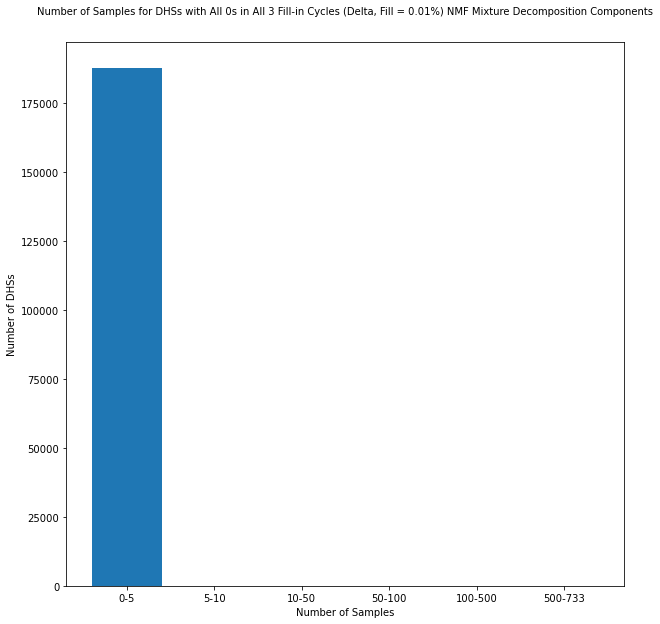

In [23]:
numsamples_nums = []
numsamples_bins = [0, 5, 10, 50, 100, 500, 733]
for i in range(1, len(numsamples_bins)):
    print(numsamples_bins[i-1])
    print(numsamples_bins[i])
    print()
    mask1 = new_decomp_Mixture_all_delta_0001_2_cycles_all_0_df['numsamples']>=numsamples_bins[i-1]
    mask2 = new_decomp_Mixture_all_delta_0001_2_cycles_all_0_df['numsamples']<numsamples_bins[i]
    numsamples_nums.append(len(new_decomp_Mixture_all_delta_0001_2_cycles_all_0_df[mask1 & mask2]))

fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')

plt.bar(['0-5', '5-10', '10-50', '50-100', '100-500', '500-733'], numsamples_nums)
plt.title('Number of Samples for DHSs with All 0s in All 3 Fill-in Cycles (Delta, Fill = 0.01%) NMF Mixture Decomposition Components', fontsize=10, y=1.04)
plt.ylabel('Number of DHSs')
plt.xlabel('Number of Samples')
plt.xticks()

0
0.1

0.1
0.5

0.5
1

1
5

5
10

10
50

50
100

100
500



([0, 1, 2, 3, 4, 5, 6, 7],
 [Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, '')])

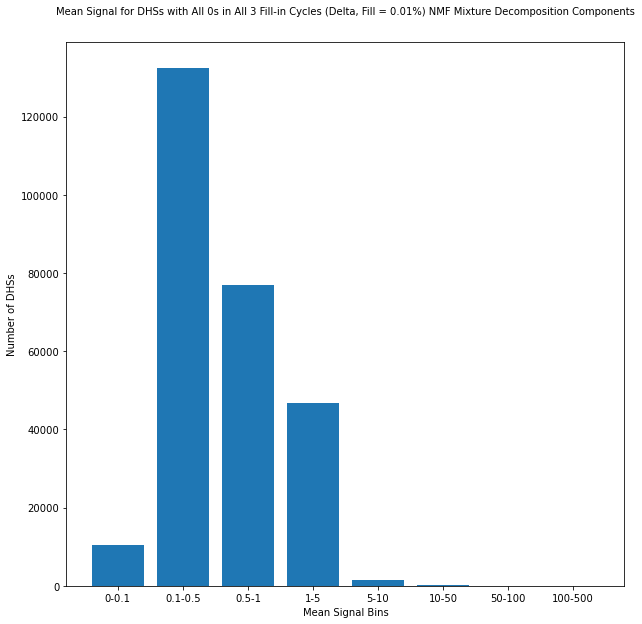

In [24]:
mean_signal_nums = []
mean_signal_bins = [0, 0.1, 0.5, 1, 5, 10, 50, 100, 500]
for i in range(1, len(mean_signal_bins)):
    print(mean_signal_bins[i-1])
    print(mean_signal_bins[i])
    print()
    mask1 = new_decomp_Mixture_all_delta_0001_3_cycles_all_0_df['mean_signal']>=mean_signal_bins[i-1]
    mask2 = new_decomp_Mixture_all_delta_0001_3_cycles_all_0_df['mean_signal']<mean_signal_bins[i]
    mean_signal_nums.append(len(new_decomp_Mixture_all_delta_0001_3_cycles_all_0_df[mask1 & mask2]))

fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')

plt.bar(['0-0.1', '0.1-0.5', '0.5-1', '1-5', '5-10', '10-50', '50-100', '100-500'], mean_signal_nums)
plt.title('Mean Signal for DHSs with All 0s in All 3 Fill-in Cycles (Delta, Fill = 0.01%) NMF Mixture Decomposition Components', fontsize=10, y=1.04)
plt.ylabel('Number of DHSs')
plt.xlabel('Mean Signal Bins')
plt.xticks()

Placental / trophoblast
Lymphoid
Myeloid / erythroid
Cardiac
Musculoskeletal
Vascular / endothelial
Primitive / embryonic
Neural
Digestive
Stromal A
Stromal B
Renal / cancer
Cancer / epithelial
Pulmonary devel.
Organ devel. / renal
Tissue invariant


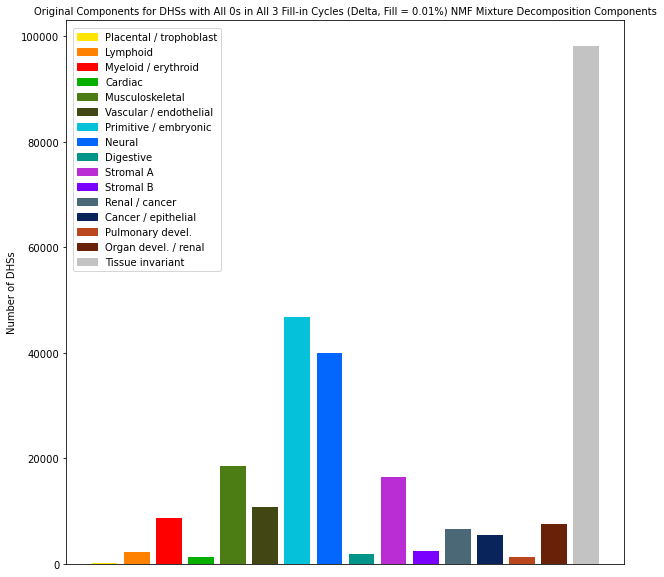

In [27]:
comp_nums = []
for comp in comps:
    print(comp)
    comp_nums.append(len(new_decomp_Mixture_all_delta_0001_3_cycles_all_0_df[new_decomp_Mixture_all_delta_0001_3_cycles_all_0_df['component']==comp]))

fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')

plt.bar(comps, comp_nums, color=color)
plt.title('Original Components for DHSs with All 0s in All 3 Fill-in Cycles (Delta, Fill = 0.01%) NMF Mixture Decomposition Components', fontsize=10)
plt.ylabel('Number of DHSs')
plt.xticks([])
handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
fig.legend(handles, comps, loc = (0.11, 0.53))

In [34]:
new_decomp_Mixture_delta_0001_1_cycle

array([[0.00145566, 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.00073171, 0.00084772,
        0.00084772],
       ...,
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.01253188, 0.        ,
        0.        ]])

In [34]:
#only the first number of 0 inds is correct here, the other 2 were calculated incorrectly - CT20211221
print(len(new_decomp_Mixture_delta_01_1_cycle_all_0_inds))
print(len(new_decomp_Mixture_delta_01_2_cycles_all_0_inds))
print(len(new_decomp_Mixture_delta_01_3_cycles_all_0_inds))

2577991
1013907
1013907


In [19]:
#these should be pickled in and re-calculated, somehow the mixture decomps are getting saved over after they are pickled - CT20211221
print(len(new_decomp_Mixture_delta_0001_1_cycle_all_0_inds))
print(len(new_decomp_Mixture_delta_0001_2_cycles_all_0_inds))
print(len(new_decomp_Mixture_delta_0001_3_cycles_all_0_inds))

111469
111469
111469


In [28]:
#these should be correct - CT20211221
print(len(new_decomp_Mixture_all_delta_0001_1_cycle_all_0_inds))
print(len(new_decomp_Mixture_all_delta_0001_2_cycles_all_0_inds))
print(len(new_decomp_Mixture_all_delta_0001_3_cycles_all_0_inds))

95625
187606
268092


In [22]:
np.sum(np.sum(new_decomp_Basis_all_delta_0001_2_cycles - new_decomp_Basis_all_delta_0001_3_cycles, axis=0))

-14.76322494041625

In [15]:
original_v_delta_01_1_cycle = np.zeros((16, 16), dtype=int)
for comp1, comp2 in zip(original_decomp_Mixture_top_comps, new_decomp_Mixture_delta_01_1_cycle_top_comps):
    original_v_delta_01_1_cycle[comp1, comp2] += 1

original_v_delta_01_2_cycles = np.zeros((16, 16), dtype=int)
for comp1, comp2 in zip(original_decomp_Mixture_top_comps, new_decomp_Mixture_delta_01_2_cycles_top_comps):
    original_v_delta_01_2_cycles[comp1, comp2] += 1

original_v_delta_01_3_cycles = np.zeros((16, 16), dtype=int)
for comp1, comp2 in zip(original_decomp_Mixture_top_comps, new_decomp_Mixture_delta_01_3_cycles_top_comps):
    original_v_delta_01_3_cycles[comp1, comp2] += 1

In [20]:
original_v_delta_0001_1_cycle = np.zeros((16, 16), dtype=int)
for comp1, comp2 in zip(original_decomp_Mixture_top_comps, new_decomp_Mixture_delta_0001_1_cycle_top_comps):
    original_v_delta_0001_1_cycle[comp1, comp2] += 1

original_v_delta_0001_2_cycles = np.zeros((16, 16), dtype=int)
for comp1, comp2 in zip(original_decomp_Mixture_top_comps, new_decomp_Mixture_delta_0001_2_cycles_top_comps):
    original_v_delta_0001_2_cycles[comp1, comp2] += 1

original_v_delta_0001_3_cycles = np.zeros((16, 16), dtype=int)
for comp1, comp2 in zip(original_decomp_Mixture_top_comps, new_decomp_Mixture_delta_0001_3_cycles_top_comps):
    original_v_delta_0001_3_cycles[comp1, comp2] += 1
    
original_v_delta_0001_1_cycle_filtered = np.zeros((16, 16), dtype=int)
for comp1, comp2 in zip(original_decomp_Mixture_top_comps_filtered_cycle_1, new_decomp_Mixture_delta_0001_1_cycle_top_comps_filtered):
    original_v_delta_0001_1_cycle_filtered[comp1, comp2] += 1

original_v_delta_0001_2_cycles_filtered = np.zeros((16, 16), dtype=int)
for comp1, comp2 in zip(original_decomp_Mixture_top_comps_filtered_cycle_2, new_decomp_Mixture_delta_0001_2_cycles_top_comps_filtered):
    original_v_delta_0001_2_cycles_filtered[comp1, comp2] += 1

original_v_delta_0001_3_cycles_filtered = np.zeros((16, 16), dtype=int)
for comp1, comp2 in zip(original_decomp_Mixture_top_comps_filtered_cycle_3, new_decomp_Mixture_delta_0001_3_cycles_top_comps_filtered):
    original_v_delta_0001_3_cycles_filtered[comp1, comp2] += 1

In [29]:
original_v_all_delta_0001_1_cycle = np.zeros((16, 16), dtype=int)
for comp1, comp2 in zip(original_decomp_Mixture_top_comps, new_decomp_Mixture_all_delta_0001_1_cycle_top_comps):
    original_v_all_delta_0001_1_cycle[comp1, comp2] += 1

original_v_all_delta_0001_2_cycles = np.zeros((16, 16), dtype=int)
for comp1, comp2 in zip(original_decomp_Mixture_top_comps, new_decomp_Mixture_all_delta_0001_2_cycles_top_comps):
    original_v_all_delta_0001_2_cycles[comp1, comp2] += 1

original_v_all_delta_0001_3_cycles = np.zeros((16, 16), dtype=int)
for comp1, comp2 in zip(original_decomp_Mixture_top_comps, new_decomp_Mixture_all_delta_0001_3_cycles_top_comps):
    original_v_all_delta_0001_3_cycles[comp1, comp2] += 1
    
original_v_all_delta_0001_1_cycle_filtered = np.zeros((16, 16), dtype=int)
for comp1, comp2 in zip(original_decomp_Mixture_top_comps_filtered_cycle_1, new_decomp_Mixture_all_delta_0001_1_cycle_top_comps_filtered):
    original_v_all_delta_0001_1_cycle_filtered[comp1, comp2] += 1

original_v_all_delta_0001_2_cycles_filtered = np.zeros((16, 16), dtype=int)
for comp1, comp2 in zip(original_decomp_Mixture_top_comps_filtered_cycle_2, new_decomp_Mixture_all_delta_0001_2_cycles_top_comps_filtered):
    original_v_all_delta_0001_2_cycles_filtered[comp1, comp2] += 1

original_v_all_delta_0001_3_cycles_filtered = np.zeros((16, 16), dtype=int)
for comp1, comp2 in zip(original_decomp_Mixture_top_comps_filtered_cycle_3, new_decomp_Mixture_all_delta_0001_3_cycles_top_comps_filtered):
    original_v_all_delta_0001_3_cycles_filtered[comp1, comp2] += 1

In [26]:
print(len(new_decomp_Mixture_delta_0001_1_cycle_top_comps_filtered))
print(len(new_decomp_Mixture_delta_0001_2_cycles_top_comps_filtered))
print(len(new_decomp_Mixture_delta_0001_3_cycles_top_comps_filtered))

3480429
3480429
3480429


In [30]:
print(len(new_decomp_Mixture_all_delta_0001_1_cycle_top_comps_filtered))
print(len(new_decomp_Mixture_all_delta_0001_2_cycles_top_comps_filtered))
print(len(new_decomp_Mixture_all_delta_0001_3_cycles_top_comps_filtered))

3496273
3404292
3323806


Text(0.5, 69.0, 'DHS Component in New NMF Mixture Decomposition')

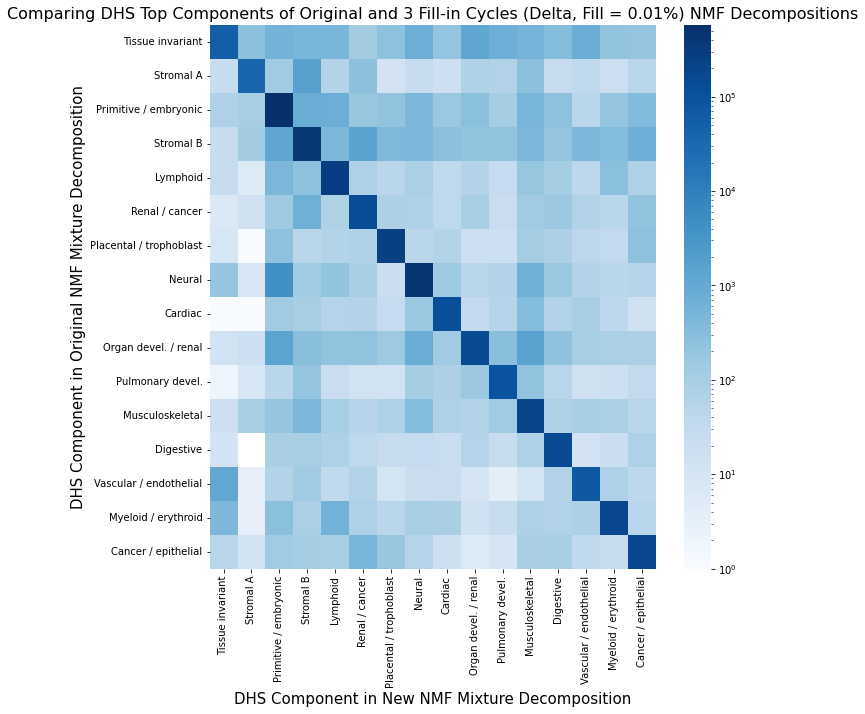

In [31]:
comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']

fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')
ax = sns.heatmap(original_v_all_delta_0001_3_cycles_filtered, cmap='Blues', cbar=True, xticklabels=comps_for_heatmap, yticklabels=comps_for_heatmap, norm=LogNorm()) # 
ax.set_title('Comparing DHS Top Components of Original and 3 Fill-in Cycles (Delta, Fill = 0.01%) NMF Decompositions', fontsize=16)
ax.set_ylabel('DHS Component in Original NMF Mixture Decomposition', fontsize=15)
ax.set_xlabel('DHS Component in New NMF Mixture Decomposition', fontsize=15)
# ax.tick_params(labelsize=9)

In [24]:
rec_info_all_delta_0001_0_cycles = heatmap_recommendations(['GM06990', 'H7_hESC_T14', 'fEye'], GM06990_signal, new_biosample_e=decomp_Basis, new_DHS_e=decomp_Mixture, print_num=0, ROIurl=True)

This is a Lymphoid Biosample
Biosample: GM06990 (0)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_GM06990_0_all_delta_0001_0_cycles_recs_CT20220105.bed
This is a Cardiac Biosample
Biosample: H7_hESC_T14 (41)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_H7_hESC_T14_41_all_delta_0001_0_cycles_recs_CT20220105.bed
This is a Neural Biosample
Biosample: fEye (561)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_fEye_561_all_delta_0001_0_cycles_recs_CT20220105.bed


In [18]:
rec_info_all_delta_0001_1_cycle = heatmap_recommendations(['GM06990', 'H7_hESC_T14', 'fEye'], GM06990_signal, new_biosample_e=new_decomp_Basis_all_delta_0001_1_cycle, new_DHS_e=new_decomp_Mixture_all_delta_0001_1_cycle, print_num=0, ROIurl=True)

This is a Lymphoid Biosample
Biosample: GM06990 (0)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_GM06990_0_all_delta_0001_1_cycle_recs_CT20220105.bed
This is a Cardiac Biosample
Biosample: H7_hESC_T14 (41)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_H7_hESC_T14_41_all_delta_0001_1_cycle_recs_CT20220105.bed
This is a Neural Biosample
Biosample: fEye (561)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_fEye_561_all_delta_0001_1_cycle_recs_CT20220105.bed


In [20]:
rec_info_all_delta_0001_2_cycles = heatmap_recommendations(['GM06990', 'H7_hESC_T14', 'fEye'], GM06990_signal, new_biosample_e=new_decomp_Basis_all_delta_0001_2_cycles, new_DHS_e=new_decomp_Mixture_all_delta_0001_2_cycles, print_num=0, ROIurl=True)

This is a Lymphoid Biosample
Biosample: GM06990 (0)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_GM06990_0_all_delta_0001_2_cycles_recs_CT20220105.bed
This is a Cardiac Biosample
Biosample: H7_hESC_T14 (41)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_H7_hESC_T14_41_all_delta_0001_2_cycles_recs_CT20220105.bed
This is a Neural Biosample
Biosample: fEye (561)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_fEye_561_all_delta_0001_2_cycles_recs_CT20220105.bed


In [15]:
rec_info_all_delta_0001_3_cycles = heatmap_recommendations(['GM06990', 'H7_hESC_T14', 'fEye'], GM06990_signal, new_biosample_e=new_decomp_Basis_all_delta_0001_3_cycles, new_DHS_e=new_decomp_Mixture_all_delta_0001_3_cycles, print_num=0, ROIurl=True)

This is a Lymphoid Biosample
Biosample: GM06990 (0)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_GM06990_0_all_delta_0001_3_cycles_recs_CT20220105.bed
This is a Cardiac Biosample
Biosample: H7_hESC_T14 (41)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_H7_hESC_T14_41_all_delta_0001_3_cycles_recs_CT20220105.bed
This is a Neural Biosample
Biosample: fEye (561)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_fEye_561_all_delta_0001_3_cycles_recs_CT20220105.bed


In [58]:
comps = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

official_order = np.array([6, 4, 14, 8, 11, 13, 2, 7, 12, 1, 3, 5, 15, 10, 9, 0])
color = np.array(color)[official_order]
comps = np.array(comps)[official_order]

k_vals = list(range(1, 1000))
k_vals.extend(list(np.arange(1000, n_DHSs, 10000)))
print(len(k_vals))

1359


In [59]:
#Component preceision and recall
all_delta_0001_0_cycles_comp_precision = []
all_delta_0001_0_cycles_comp_recall = []
for sample in range(len(rec_info_all_delta_0001_0_cycles)):
    all_comps_precision = []
    all_comps_recall = []
    for comp in comps:
        p, r = component_precision_multiple_k(rec_info_all_delta_0001_0_cycles[sample], comp, k_vals)
        all_comps_precision.append(p)
        all_comps_recall.append(r)
    all_delta_0001_0_cycles_comp_precision.append(all_comps_precision)
    all_delta_0001_0_cycles_comp_recall.append(all_comps_recall)

/tmp/ipykernel_175388/311271341.py:176: RuntimeWarning: invalid value encountered in true_divide
  recall = counts/total_of_comp


In [60]:
#Component preceision and recall
all_delta_0001_1_cycle_comp_precision = []
all_delta_0001_1_cycle_comp_recall = []
for sample in range(len(rec_info_all_delta_0001_1_cycle)):
    all_comps_precision = []
    all_comps_recall = []
    for comp in comps:
        p, r = component_precision_multiple_k(rec_info_all_delta_0001_1_cycle[sample], comp, k_vals)
        all_comps_precision.append(p)
        all_comps_recall.append(r)
    all_delta_0001_1_cycle_comp_precision.append(all_comps_precision)
    all_delta_0001_1_cycle_comp_recall.append(all_comps_recall)

In [61]:
#Component preceision and recall
all_delta_0001_2_cycles_comp_precision = []
all_delta_0001_2_cycles_comp_recall = []
for sample in range(len(rec_info_all_delta_0001_2_cycles)):
    all_comps_precision = []
    all_comps_recall = []
    for comp in comps:
        p, r = component_precision_multiple_k(rec_info_all_delta_0001_2_cycles[sample], comp, k_vals)
        all_comps_precision.append(p)
        all_comps_recall.append(r)
    all_delta_0001_2_cycles_comp_precision.append(all_comps_precision)
    all_delta_0001_2_cycles_comp_recall.append(all_comps_recall)

In [62]:
#Component preceision and recall
all_delta_0001_3_cycles_comp_precision = []
all_delta_0001_3_cycles_comp_recall = []
for sample in range(len(rec_info_all_delta_0001_3_cycles)):
    all_comps_precision = []
    all_comps_recall = []
    for comp in comps:
        p, r = component_precision_multiple_k(rec_info_all_delta_0001_3_cycles[sample], comp, k_vals)
        all_comps_precision.append(p)
        all_comps_recall.append(r)
    all_delta_0001_3_cycles_comp_precision.append(all_comps_precision)
    all_delta_0001_3_cycles_comp_recall.append(all_comps_recall)

Text(-0.01, 0.5, 'Precision@k')

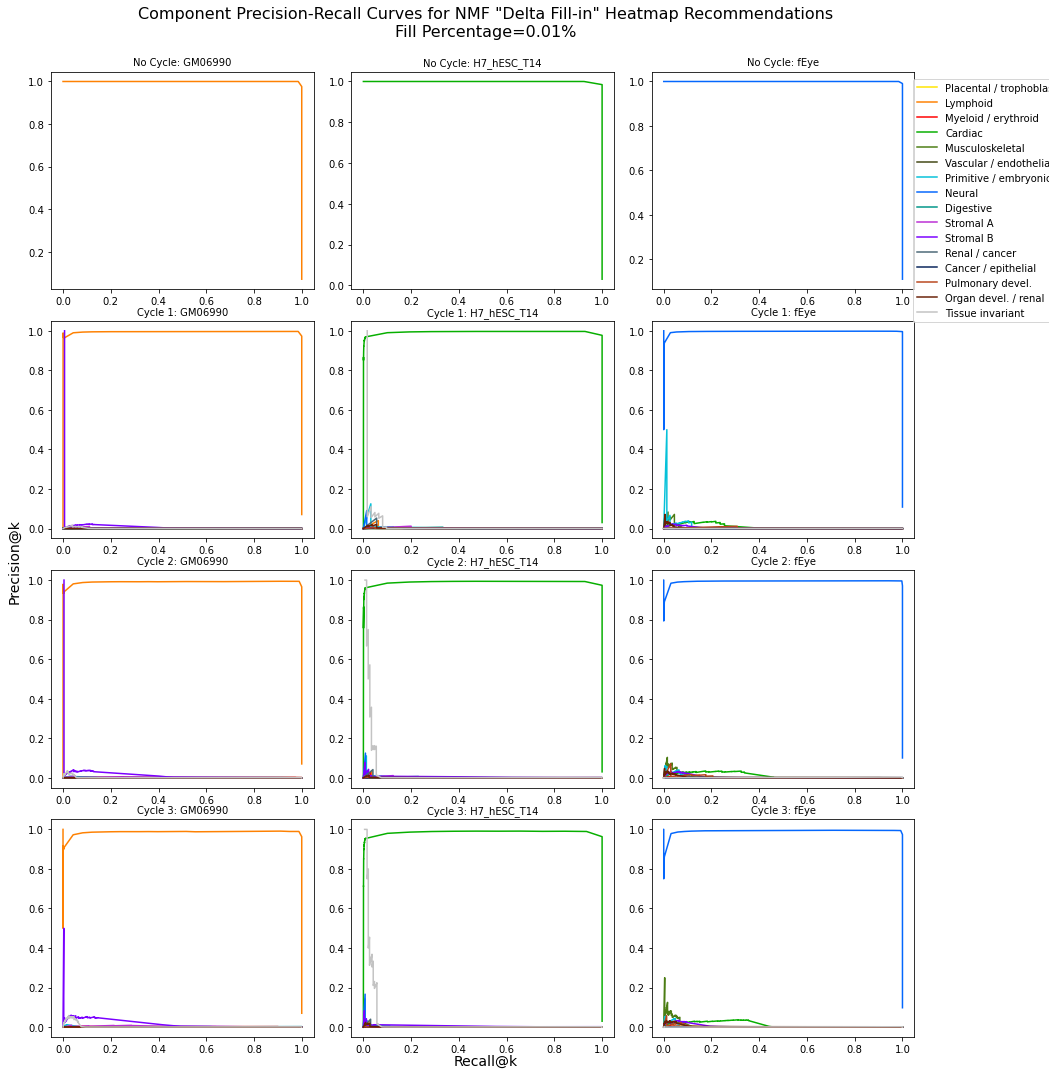

In [63]:
biosample_names = ['GM06990', 'H7_hESC_T14', 'fEye']

fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(14,14))
fig.tight_layout()
fig.patch.set_facecolor('white')

for ax, ind in zip(fig.axes[:3], range(3)):
    for i in range(len(comps)):
        ax.plot(all_delta_0001_0_cycles_comp_recall[ind][i], all_delta_0001_0_cycles_comp_precision[ind][i], color=color[i])
    ax.set_title('No Cycle: ' + biosample_names[ind], fontsize=10)

for ax, ind in zip(fig.axes[3:6], range(3)):
    for i in range(len(comps)):
        ax.plot(all_delta_0001_1_cycle_comp_recall[ind][i], all_delta_0001_1_cycle_comp_precision[ind][i], color=color[i])
    ax.set_title('Cycle 1: ' + biosample_names[ind], fontsize=10)
    
for ax, ind in zip(fig.axes[6:9], range(3)):
    for i in range(len(comps)):
        ax.plot(all_delta_0001_2_cycles_comp_recall[ind][i], all_delta_0001_2_cycles_comp_precision[ind][i], color=color[i])
    ax.set_title('Cycle 2: ' + biosample_names[ind], fontsize=10)
    
for ax, ind in zip(fig.axes[9:12], range(3)):
    for i in range(len(comps)):
        ax.plot(all_delta_0001_3_cycles_comp_recall[ind][i], all_delta_0001_3_cycles_comp_precision[ind][i], color=color[i])
    ax.set_title('Cycle 3: ' + biosample_names[ind], fontsize=10)


fig.subplots_adjust(right=0.89)
# lines, labels = fig.axes[-1].get_legend_handles_labels()
fig.legend(comps, loc = (0.87, 0.7))
# print(lines)
fig.suptitle('Component Precision-Recall Curves for NMF "Delta Fill-in" Heatmap Recommendations\nFill Percentage=0.01%', fontsize=16, x=0.465, y=1.05)
# fig.xlabel('Recall@k')
# fig.ylabel('Precision@k')
fig.text(0.465, 0, 'Recall@k', ha='center', fontsize=14)
fig.text(-0.01, 0.5, 'Precision@k', va='center', rotation='vertical', fontsize=14)

**Using Fill in (Decision Boundary) function**

In [27]:
updated_dhs_array_decision_boundary_1_cycle, new_decomp_Basis_decision_boundary_1_cycle, new_decomp_Mixture_decision_boundary_1_cycle = fill_in_decision_boundary(Basis=decomp_Basis, Mixture=decomp_Mixture)

Starting Cycle 1 / 1
NMF Decomposition:
violation: 1.0
violation: 0.10993098304195034
violation: 0.04173847715005716
violation: 0.02467070800103393
violation: 0.017260143729858637
violation: 0.012658969941030777
violation: 0.009423577501523001
violation: 0.00731550742825827
violation: 0.005902480540869379
violation: 0.004943496728105824
violation: 0.0042601148437865
violation: 0.0037285760048777327
violation: 0.003266719022087621
violation: 0.0028351204894852752
violation: 0.002446094508755881
violation: 0.002120999014996807
violation: 0.0018493933255297218
violation: 0.0016258719725234672
violation: 0.001452035955181929
violation: 0.0013147737536612146
violation: 0.0012017453856691214
violation: 0.00111039593340025
violation: 0.0010356745094693824
violation: 0.0009729931964460942
violation: 0.0009182441635601368
violation: 0.00086784989931988
violation: 0.0008242036115885172
violation: 0.0007864165638968667
violation: 0.000753250667636549
violation: 0.0007239065616543211
violation: 0.

In [25]:
original_v_decision_boundary_1_cycle_f1 = f1_score(dhs_array, updated_dhs_array_decision_boundary_1_cycle, average='micro')

In [28]:
pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_decision_boundary_1_cycle_CT20211216.pickle', 'wb')
pickle.dump(updated_dhs_array_decision_boundary_1_cycle, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_decision_boundary_1_cycle_CT20211216.pickle', 'wb')
pickle.dump(new_decomp_Basis_decision_boundary_1_cycle, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_decision_boundary_1_cycle_CT20211216.pickle', 'wb')
pickle.dump(new_decomp_Mixture_decision_boundary_1_cycle, pickle_out)
pickle_out.close()

In [5]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_decision_boundary_1_cycle_CT20211216.pickle', 'rb')
updated_dhs_array_decision_boundary_1_cycle=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_decision_boundary_1_cycle_CT20211216.pickle', 'rb')
new_decomp_Basis_decision_boundary_1_cycle=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_decision_boundary_1_cycle_CT20211216.pickle', 'rb')
new_decomp_Mixture_decision_boundary_1_cycle=pickle.load(pickle_in)

In [29]:
updated_dhs_array_decision_boundary_2_cycles, new_decomp_Basis_decision_boundary_2_cycles, new_decomp_Mixture_decision_boundary_2_cycles = fill_in_decision_boundary(Basis=new_decomp_Basis_decision_boundary_1_cycle, Mixture=new_decomp_Mixture_decision_boundary_1_cycle)

Starting Cycle 1 / 1
NMF Decomposition:
violation: 1.0
violation: 0.1547370610240023
violation: 0.0599872869618943
violation: 0.03938930039991594
violation: 0.029049828574880934
violation: 0.021162322697325684
violation: 0.01496650932308445
violation: 0.01119784879711967
violation: 0.00887602136529387
violation: 0.007285213388054448
violation: 0.006230894166888372
violation: 0.005494893890402667
violation: 0.004971134969551983
violation: 0.00457260108395294
violation: 0.00426829780171895
violation: 0.004042540559534487
violation: 0.003854975157892549
violation: 0.0036780952689655856
violation: 0.0035179556641759253
violation: 0.0033725083606978325
violation: 0.003237226990670361
violation: 0.0031100820026642778
violation: 0.002990318207936818
violation: 0.002877208544880536
violation: 0.0027695043882040066
violation: 0.0026054833279915567
violation: 0.002419684343003724
violation: 0.0022944310862308853
violation: 0.0021830232903288596
violation: 0.0020843793384208525
violation: 0.00198

In [26]:
original_v_decision_boundary_2_cycles_f1 = f1_score(dhs_array, updated_dhs_array_decision_boundary_2_cycles, average='micro')

In [30]:
pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_decision_boundary_2_cycles_CT20211216.pickle', 'wb')
pickle.dump(updated_dhs_array_decision_boundary_2_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_decision_boundary_2_cycles_CT20211216.pickle', 'wb')
pickle.dump(new_decomp_Basis_decision_boundary_2_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_decision_boundary_2_cycles_CT20211216.pickle', 'wb')
pickle.dump(new_decomp_Mixture_decision_boundary_2_cycles, pickle_out)
pickle_out.close()

In [6]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_decision_boundary_2_cycles_CT20211216.pickle', 'rb')
updated_dhs_array_decision_boundary_2_cycles=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_decision_boundary_2_cycles_CT20211216.pickle', 'rb')
new_decomp_Basis_decision_boundary_2_cycles=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_decision_boundary_2_cycles_CT20211216.pickle', 'rb')
new_decomp_Mixture_decision_boundary_2_cycles=pickle.load(pickle_in)

In [31]:
updated_dhs_array_decision_boundary_3_cycles, new_decomp_Basis_decision_boundary_3_cycles, new_decomp_Mixture_decision_boundary_3_cycles = fill_in_decision_boundary(Basis=new_decomp_Basis_decision_boundary_2_cycles, Mixture=new_decomp_Mixture_decision_boundary_2_cycles)

Starting Cycle 1 / 1
NMF Decomposition:
violation: 1.0
violation: 0.15515536872113272
violation: 0.06559040975044535
violation: 0.04480230044474865
violation: 0.03219408270772054
violation: 0.02384191143210182
violation: 0.017991990682548403
violation: 0.012960565504674766
violation: 0.00951718644283025
violation: 0.006423210751986942
violation: 0.004955364291932329
violation: 0.004385943624357469
violation: 0.004027733787811388
violation: 0.0037566388525518894
violation: 0.00353971060145504
violation: 0.003351556455788612
violation: 0.0031762075833404865
violation: 0.0030497842388324432
violation: 0.00293293894301211
violation: 0.0028285722717487985
violation: 0.0027328419707892777
violation: 0.0026456120714518395
violation: 0.0023763765764412987
violation: 0.0021351432505343246
violation: 0.0020231025066502137
violation: 0.0019331809192538406
violation: 0.0018587036441551927
violation: 0.001798084670555407
violation: 0.0017439994679512836
violation: 0.0016939614416165928
violation: 0

In [27]:
original_v_decision_boundary_3_cycles_f1 = f1_score(dhs_array, updated_dhs_array_decision_boundary_3_cycles, average='micro')

In [28]:
print(original_v_decision_boundary_1_cycle_f1)
print(original_v_decision_boundary_2_cycles_f1)
print(original_v_decision_boundary_3_cycles_f1)

0.6961878903189619
0.6646190904526816
0.648004340415042


In [32]:
pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_decision_boundary_3_cycles_CT20211216.pickle', 'wb')
pickle.dump(updated_dhs_array_decision_boundary_3_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_decision_boundary_3_cycles_CT20211216.pickle', 'wb')
pickle.dump(new_decomp_Basis_decision_boundary_3_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_decision_boundary_3_cycles_CT20211216.pickle', 'wb')
pickle.dump(new_decomp_Mixture_decision_boundary_3_cycles, pickle_out)
pickle_out.close()

In [7]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_decision_boundary_3_cycles_CT20211216.pickle', 'rb')
updated_dhs_array_decision_boundary_3_cycles=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_decision_boundary_3_cycles_CT20211216.pickle', 'rb')
new_decomp_Basis_decision_boundary_3_cycles=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_decision_boundary_3_cycles_CT20211216.pickle', 'rb')
new_decomp_Mixture_decision_boundary_3_cycles=pickle.load(pickle_in)

In [ ]:
print(1-(np.sum(np.sum(dhs_array, axis=0))/(n_DHSs*n_biosamples)))
print(1-(np.sum(np.sum(updated_dhs_array_decision_boundary_1_cycle, axis=0))/(n_DHSs*n_biosamples)))
print(1-(np.sum(np.sum(updated_dhs_array_decision_boundary_2_cycles, axis=0))/(n_DHSs*n_biosamples)))
print(1-(np.sum(np.sum(updated_dhs_array_decision_boundary_3_cycles, axis=0))/(n_DHSs*n_biosamples)))

In [8]:
original_decomp_Mixture_top_comps = np.argmax(decomp_Mixture, axis=0)
new_decomp_Mixture_decision_boundary_1_cycle_top_comps = np.argmax(new_decomp_Mixture_decision_boundary_1_cycle, axis=0)
new_decomp_Mixture_decision_boundary_2_cycles_top_comps = np.argmax(new_decomp_Mixture_decision_boundary_2_cycles, axis=0)
new_decomp_Mixture_decision_boundary_3_cycles_top_comps = np.argmax(new_decomp_Mixture_decision_boundary_3_cycles, axis=0)
# test_top_comps = np.argmax(test_Mixture, axis=0)
# test_1_cycle_top_comps = np.argmax(test_Mixture_1_cycle, axis=0)

In [9]:
#filtering out indices where all comps=0
new_decomp_Mixture_decision_boundary_1_cycle_sum = np.sum(new_decomp_Mixture_decision_boundary_1_cycle, axis=0)
all_dhs_inds = np.arange(0, len(new_decomp_Mixture_decision_boundary_1_cycle_sum))
new_decomp_Mixture_decision_boundary_1_cycle_top_comps_filtered = new_decomp_Mixture_decision_boundary_1_cycle_top_comps[new_decomp_Mixture_decision_boundary_1_cycle_sum!=0]
new_decomp_Mixture_decision_boundary_1_cycle_all_0_inds = all_dhs_inds[new_decomp_Mixture_decision_boundary_1_cycle_sum==0]
original_decomp_Mixture_top_comps_filtered_cycle_1 = original_decomp_Mixture_top_comps[new_decomp_Mixture_decision_boundary_1_cycle_sum!=0]

new_decomp_Mixture_decision_boundary_2_cycles_sum = np.sum(new_decomp_Mixture_decision_boundary_2_cycles, axis=0)
new_decomp_Mixture_decision_boundary_2_cycles_top_comps_filtered = new_decomp_Mixture_decision_boundary_2_cycles_top_comps[new_decomp_Mixture_decision_boundary_2_cycles_sum!=0]
new_decomp_Mixture_decision_boundary_2_cycles_all_0_inds = all_dhs_inds[new_decomp_Mixture_decision_boundary_2_cycles_sum==0]
original_decomp_Mixture_top_comps_filtered_cycle_2 = original_decomp_Mixture_top_comps[new_decomp_Mixture_decision_boundary_2_cycles_sum!=0]

new_decomp_Mixture_decision_boundary_3_cycles_sum = np.sum(new_decomp_Mixture_decision_boundary_3_cycles, axis=0)
new_decomp_Mixture_decision_boundary_3_cycles_top_comps_filtered = new_decomp_Mixture_decision_boundary_3_cycles_top_comps[new_decomp_Mixture_decision_boundary_3_cycles_sum!=0]
new_decomp_Mixture_decision_boundary_3_cycles_all_0_inds = all_dhs_inds[new_decomp_Mixture_decision_boundary_3_cycles_sum==0]
original_decomp_Mixture_top_comps_filtered_cycle_3 = original_decomp_Mixture_top_comps[new_decomp_Mixture_decision_boundary_3_cycles_sum!=0]

In [31]:
print(len(new_decomp_Mixture_decision_boundary_1_cycle_all_0_inds))
print(len(new_decomp_Mixture_decision_boundary_2_cycles_all_0_inds))
print(len(new_decomp_Mixture_decision_boundary_3_cycles_all_0_inds))

2605767
2759954
2774488


In [35]:
len(new_decomp_Mixture_decision_boundary_3_cycles_all_0_inds)

2774488

In [36]:
n_DHSs - len(new_decomp_Mixture_decision_boundary_2_cycles_all_0_inds)

831944

In [26]:
new_decomp_Mixture_decision_boundary_2_cycles[:, 3591897]

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [38]:
len(new_decomp_Mixture_decision_boundary_1_cycle_all_0_inds) - len(new_decomp_Mixture_decision_boundary_2_cycles_all_0_inds) 

-154187

In [115]:
new_decomp_Mixture_decision_boundary_1_cycle[:, 23]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.00620769,
       0.        ])

In [18]:
new_decomp_Mixture_decision_boundary_1_cycle_all_0_df = DHS_metadata.loc[new_decomp_Mixture_decision_boundary_1_cycle_all_0_inds]
new_decomp_Mixture_decision_boundary_2_cycles_all_0_df = DHS_metadata.loc[new_decomp_Mixture_decision_boundary_2_cycles_all_0_inds]
new_decomp_Mixture_decision_boundary_3_cycles_all_0_df = DHS_metadata.loc[new_decomp_Mixture_decision_boundary_3_cycles_all_0_inds]

In [19]:
new_decomp_Mixture_decision_boundary_1_cycle_all_0_df['mean_signal'] = new_decomp_Mixture_decision_boundary_1_cycle_all_0_df['mean_signal'].astype(float)
new_decomp_Mixture_decision_boundary_2_cycles_all_0_df['mean_signal'] = new_decomp_Mixture_decision_boundary_2_cycles_all_0_df['mean_signal'].astype(float)
new_decomp_Mixture_decision_boundary_3_cycles_all_0_df['mean_signal'] = new_decomp_Mixture_decision_boundary_3_cycles_all_0_df['mean_signal'].astype(float)

new_decomp_Mixture_decision_boundary_1_cycle_all_0_df['numsamples'] = new_decomp_Mixture_decision_boundary_1_cycle_all_0_df['numsamples'].astype(int)
new_decomp_Mixture_decision_boundary_2_cycles_all_0_df['numsamples'] = new_decomp_Mixture_decision_boundary_2_cycles_all_0_df['numsamples'].astype(int)
new_decomp_Mixture_decision_boundary_3_cycles_all_0_df['numsamples'] = new_decomp_Mixture_decision_boundary_3_cycles_all_0_df['numsamples'].astype(int)



In [44]:
new_decomp_Mixture_decision_boundary_3_cycles_all_0_df['mean_signal'].max()

278.297325

In [20]:
numsamples_nums = []
numsamples_bins = [0, 5, 10, 50, 100, 500, 733]
for i in range(1, len(numsamples_bins)):
    print(numsamples_bins[i-1])
    print(numsamples_bins[i])
    print()
    mask1 = new_decomp_Mixture_decision_boundary_3_cycles_all_0_df['numsamples']>=numsamples_bins[i-1]
    mask2 = new_decomp_Mixture_decision_boundary_3_cycles_all_0_df['numsamples']<numsamples_bins[i]
    numsamples_nums.append(len(new_decomp_Mixture_decision_boundary_3_cycles_all_0_df[mask1 & mask2]))

0
5

5
10

10
50

50
100

100
500

500
733



([0, 1, 2, 3, 4, 5],
 [Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, '')])

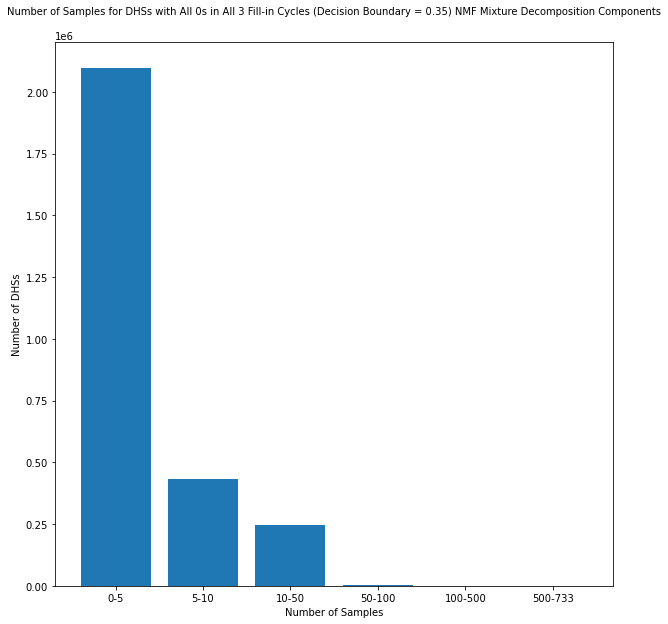

In [21]:
fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')

plt.bar(['0-5', '5-10', '10-50', '50-100', '100-500', '500-733'], numsamples_nums)
plt.title('Number of Samples for DHSs with All 0s in All 3 Fill-in Cycles (Decision Boundary = 0.35) NMF Mixture Decomposition Components', fontsize=10, y=1.04)
plt.ylabel('Number of DHSs')
plt.xlabel('Number of Samples')
plt.xticks()

In [22]:
mean_signal_nums = []
mean_signal_bins = [0, 0.1, 0.5, 1, 5, 10, 50, 100, 500]
for i in range(1, len(mean_signal_bins)):
    print(mean_signal_bins[i-1])
    print(mean_signal_bins[i])
    print()
    mask1 = new_decomp_Mixture_decision_boundary_3_cycles_all_0_df['mean_signal']>=mean_signal_bins[i-1]
    mask2 = new_decomp_Mixture_decision_boundary_3_cycles_all_0_df['mean_signal']<mean_signal_bins[i]
    mean_signal_nums.append(len(new_decomp_Mixture_decision_boundary_3_cycles_all_0_df[mask1 & mask2]))

0
0.1

0.1
0.5

0.5
1

1
5

5
10

10
50

50
100

100
500



([0, 1, 2, 3, 4, 5, 6, 7],
 [Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, '')])

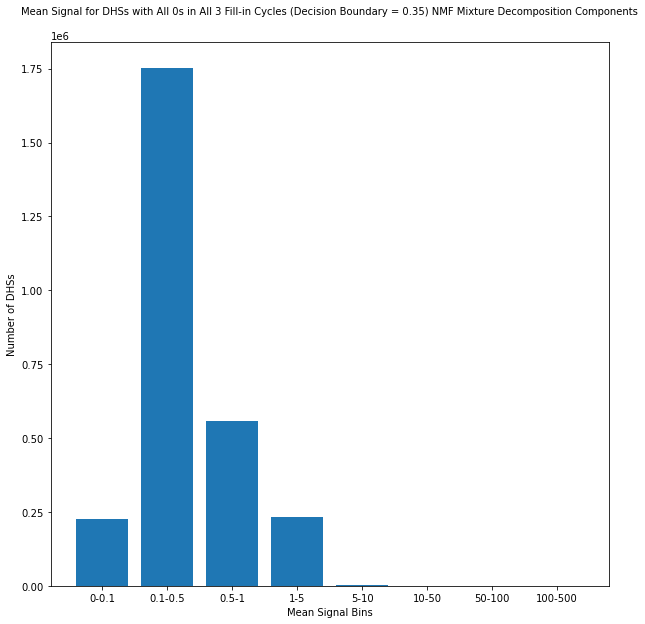

In [23]:
fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')

plt.bar(['0-0.1', '0.1-0.5', '0.5-1', '1-5', '5-10', '10-50', '50-100', '100-500'], mean_signal_nums)
plt.title('Mean Signal for DHSs with All 0s in All 3 Fill-in Cycles (Decision Boundary = 0.35) NMF Mixture Decomposition Components', fontsize=10, y=1.04)
plt.ylabel('Number of DHSs')
plt.xlabel('Mean Signal Bins')
plt.xticks()
# handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
# fig.legend(handles, comps, loc = (0.68, 0.53))

In [27]:
comp_nums = []
for comp in comps:
    comp_nums.append(len(new_decomp_Mixture_decision_boundary_3_cycles_all_0_df[new_decomp_Mixture_decision_boundary_3_cycles_all_0_df['component']==comp]))

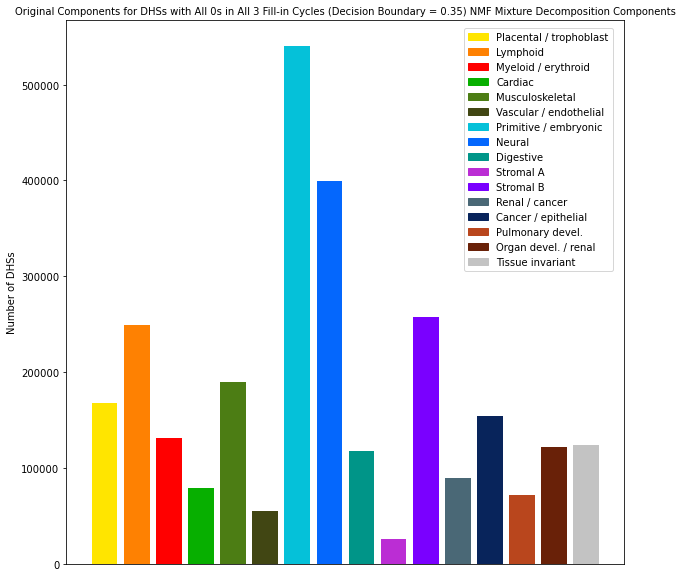

In [29]:
fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')

plt.bar(comps, comp_nums, color=color)
plt.title('Original Components for DHSs with All 0s in All 3 Fill-in Cycles (Decision Boundary = 0.35) NMF Mixture Decomposition Components', fontsize=10)
plt.ylabel('Number of DHSs')
plt.xticks([])
handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
fig.legend(handles, comps, loc = (0.68, 0.53))

In [30]:
dhs_array_sum = np.sum(dhs_array, axis=0)
print(len(dhs_array_sum[dhs_array_sum==0]))

updated_dhs_array_decision_boundary_1_cycle_sum = np.sum(updated_dhs_array_decision_boundary_1_cycle, axis=0)
print(len(updated_dhs_array_decision_boundary_1_cycle_sum[updated_dhs_array_decision_boundary_1_cycle_sum==0]))

updated_dhs_array_decision_boundary_2_cycles_sum = np.sum(updated_dhs_array_decision_boundary_2_cycles, axis=0)
print(len(updated_dhs_array_decision_boundary_2_cycles_sum[updated_dhs_array_decision_boundary_2_cycles_sum==0]))

updated_dhs_array_decision_boundary_3_cycles_sum = np.sum(updated_dhs_array_decision_boundary_3_cycles, axis=0)
print(len(updated_dhs_array_decision_boundary_3_cycles_sum[updated_dhs_array_decision_boundary_3_cycles_sum==0]))

0
2605767
2759954
2774488


In [88]:
original_v_decision_boundary_1_cycle = np.zeros((16, 16), dtype=int)
for comp1, comp2 in zip(original_decomp_Mixture_top_comps, new_decomp_Mixture_decision_boundary_1_cycle_top_comps):
    original_v_decision_boundary_1_cycle[comp1, comp2] += 1

original_v_decision_boundary_2_cycles = np.zeros((16, 16), dtype=int)
for comp1, comp2 in zip(original_decomp_Mixture_top_comps, new_decomp_Mixture_decision_boundary_2_cycles_top_comps):
    original_v_decision_boundary_2_cycles[comp1, comp2] += 1

original_v_decision_boundary_3_cycles = np.zeros((16, 16), dtype=int)
for comp1, comp2 in zip(original_decomp_Mixture_top_comps, new_decomp_Mixture_decision_boundary_3_cycles_top_comps):
    original_v_decision_boundary_3_cycles[comp1, comp2] += 1
    
# original_v_test = np.zeros((16, 16), dtype=int)
# for comp1, comp2 in zip(original_decomp_Mixture_top_comps, test_top_comps):
#     original_v_test[comp1, comp2] += 1
    
# original_v_test_1_cycle = np.zeros((16, 16), dtype=int)
# for comp1, comp2 in zip(original_decomp_Mixture_top_comps, test_1_cycle_top_comps):
#     original_v_test_1_cycle[comp1, comp2] += 1

#filtered top comps
original_filtered_v_decision_boundary_1_cycle_filtered = np.zeros((16, 16), dtype=int)
for comp1, comp2 in zip(original_decomp_Mixture_top_comps_filtered_cycle_1, new_decomp_Mixture_decision_boundary_1_cycle_top_comps_filtered):
    original_filtered_v_decision_boundary_1_cycle_filtered[comp1, comp2] += 1
    
original_filtered_v_decision_boundary_2_cycles_filtered = np.zeros((16, 16), dtype=int)
for comp1, comp2 in zip(original_decomp_Mixture_top_comps_filtered_cycle_2, new_decomp_Mixture_decision_boundary_2_cycles_top_comps_filtered):
    original_filtered_v_decision_boundary_2_cycles_filtered[comp1, comp2] += 1
    
original_filtered_v_decision_boundary_3_cycles_filtered = np.zeros((16, 16), dtype=int)
for comp1, comp2 in zip(original_decomp_Mixture_top_comps_filtered_cycle_3, new_decomp_Mixture_decision_boundary_3_cycles_top_comps_filtered):
    original_filtered_v_decision_boundary_3_cycles_filtered[comp1, comp2] += 1

In [3]:
comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']

Text(0.5, 69.0, 'DHS Component in New NMF Mixture Decomposition')

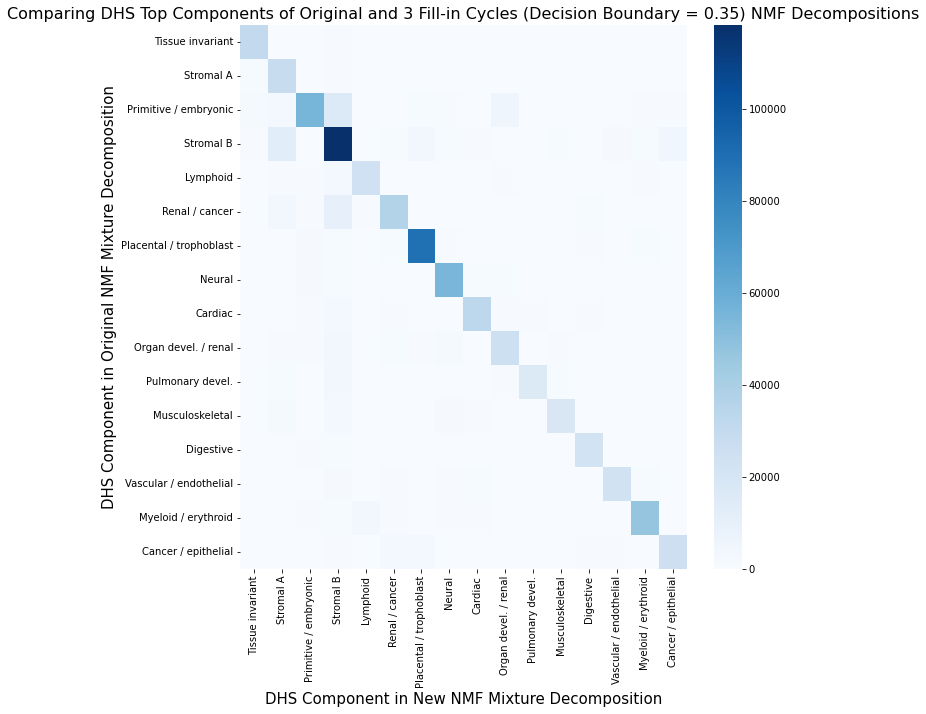

In [162]:
fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')
ax = sns.heatmap(original_filtered_v_decision_boundary_3_cycles_filtered, cmap='Blues', cbar=True, xticklabels=comps_for_heatmap, yticklabels=comps_for_heatmap) # 
ax.set_title('Comparing DHS Top Components of Original and 3 Fill-in Cycles (Decision Boundary = 0.35) NMF Decompositions', fontsize=16)
ax.set_ylabel('DHS Component in Original NMF Mixture Decomposition', fontsize=15)
ax.set_xlabel('DHS Component in New NMF Mixture Decomposition', fontsize=15)
# ax.tick_params(labelsize=9)

In [35]:
# test_Basis, test_Mixture, n_iter = non_negative_factorization(dhs_array, n_components=16, init='nndsvd', random_state=3, max_iter=400, verbose=1)

In [36]:
# test_Basis_1_cycle, test_Mixture_1_cycle, n_iter = non_negative_factorization(updated_dhs_array_decision_boundary_1_cycle, n_components=16, init='nndsvd', random_state=3, max_iter=400, verbose=1)

**Using Fill in (keep proportions) function**

In [99]:
updated_dhs_array_keep_proportions_1_cycle, new_decomp_Basis_keep_proportions_1_cycle, new_decomp_Mixture_keep_proportions_1_cycle = fill_in_keep_proportions(cycles=1)

Starting Cycle 1 / 1
NMF Decomposition:
violation: 1.0
violation: 0.12986113168935137
violation: 0.05217660547637487
violation: 0.03286451699354555
violation: 0.023891869505208985
violation: 0.01791441027852827
violation: 0.013746921462912367
violation: 0.010845590450917974
violation: 0.008879140899171516
violation: 0.007451027149041496
violation: 0.00647537037106675
violation: 0.005682738293313174
violation: 0.005006082109146308
violation: 0.004440449855319323
violation: 0.003945920804978933
violation: 0.0035259973940055906
violation: 0.0031760225340073476
violation: 0.0028889820922166276
violation: 0.0026476870813336956
violation: 0.0024471808309172822
violation: 0.0022741967418946733
violation: 0.0021266742617592647
violation: 0.002000382472598775
violation: 0.001893498824551247
violation: 0.0018000744369726317
violation: 0.0017182175047163106
violation: 0.0016453134883057203
violation: 0.0015792890646031392
violation: 0.0015198273209234114
violation: 0.00146545259721906
violation: 

In [100]:
pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_keep_proportions_updated_dhs_array_1_cycle_CT20211213.pickle', 'wb')
pickle.dump(updated_dhs_array_keep_proportions_1_cycle, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_keep_proportions_new_decomp_Basis_1_cycle_CT20211213.pickle', 'wb')
pickle.dump(new_decomp_Basis_keep_proportions_1_cycle, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_keep_proportions_new_decomp_Mixture_1_cycle_CT20211213.pickle', 'wb')
pickle.dump(new_decomp_Mixture_keep_proportions_1_cycle, pickle_out)
pickle_out.close()

In [11]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_keep_proportions_updated_dhs_array_1_cycle_CT20211213.pickle', 'rb')
updated_dhs_array_keep_proportions_1_cycle=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_keep_proportions_new_decomp_Basis_1_cycle_CT20211213.pickle', 'rb')
new_decomp_Basis_keep_proportions_1_cycle=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_keep_proportions_new_decomp_Mixture_1_cycle_CT20211213.pickle', 'rb')
new_decomp_Mixture_keep_proportions_1_cycle=pickle.load(pickle_in)

In [16]:
dhs_array - updated_dhs_array_keep_proportions_1_cycle

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [101]:
np.sum(np.sum(updated_dhs_array_keep_proportions_1_cycle, axis=1))/(n_biosamples*n_DHSs)

0.02897134722292774

In [102]:
np.sum(np.sum(dhs_array, axis=1))/(n_biosamples*n_DHSs)

0.02897134722292774

**Using Fill in (add positives) Function**

In [13]:
updated_dhs_array_1_cycle, new_decomp_Basis_1_cycle, new_decomp_Mixture_1_cycle = fill_in(cut_size=10000, cycles=1)

Starting Cycle 1 / 1
difference check: 7330000
NMF Decomposition:
violation: 1.0
violation: 0.22994449262030303
violation: 0.09795133939950146
violation: 0.06619030850214343
violation: 0.05047942813275997
violation: 0.039804322451766516
violation: 0.03210103711996027
violation: 0.026347708356290165
violation: 0.02184029069637115
violation: 0.018298405484414994
violation: 0.015406403545629771
violation: 0.01298326417539469
violation: 0.010992525452903436
violation: 0.00936567163266433
violation: 0.008018351839919183
violation: 0.006898775117827442
violation: 0.005966105027541934
violation: 0.005193458714132423
violation: 0.004538689673063253
violation: 0.003986330484607672
violation: 0.0035193769382953345
violation: 0.0031305237117573116
violation: 0.0028101852966990496
violation: 0.00254413876682222
violation: 0.002320648433059749
violation: 0.002130973899588771
violation: 0.001971627675589798
violation: 0.0018347952785097408
violation: 0.0017172035510155345
violation: 0.00161516527506

In [14]:
pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_1_cycle_fill_10000_CT20211209.pickle', 'wb')
pickle.dump(updated_dhs_array_1_cycle, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_1_cycle_fill_10000_CT20211209.pickle', 'wb')
pickle.dump(new_decomp_Basis_1_cycle, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_1_cycle_fill_10000_CT20211209.pickle', 'wb')
pickle.dump(new_decomp_Mixture_1_cycle, pickle_out)
pickle_out.close()

In [13]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_1_cycle_fill_10000_CT20211209.pickle', 'rb')
updated_dhs_array_1_cycle=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_1_cycle_fill_10000_CT20211209.pickle', 'rb')
new_decomp_Basis_1_cycle=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_1_cycle_fill_10000_CT20211209.pickle', 'rb')
new_decomp_Mixture_1_cycle=pickle.load(pickle_in)

In [14]:
updated_dhs_array_2_cycles, new_decomp_Basis_2_cycles, new_decomp_Mixture_2_cycles = fill_in(Basis=new_decomp_Basis_1_cycle, Mixture=new_decomp_Mixture_1_cycle, dhs_arr=updated_dhs_array_1_cycle, cut_size=10000, cycles=1)

Starting Cycle 1 / 1
difference check: 7330000
NMF Decomposition:
violation: 1.0
violation: 0.23616120232741442
violation: 0.09751479942170455
violation: 0.06056155815234619
violation: 0.043458745335063026
violation: 0.033123398464114565
violation: 0.026379168989746172
violation: 0.02154475017677024
violation: 0.01794426197206815
violation: 0.015271319613596759
violation: 0.01322367707035115
violation: 0.011679586846517029
violation: 0.010447131717450394
violation: 0.009454430685563382
violation: 0.008646141898800579
violation: 0.007991690655033603
violation: 0.0074504532402603985
violation: 0.006993558757159101
violation: 0.006604521061481325
violation: 0.006273887224141319
violation: 0.005993879884434597
violation: 0.005753731393447172
violation: 0.005545461100306815
violation: 0.005361509591134853
violation: 0.005195791166990095
violation: 0.005043674277075612
violation: 0.0049007555553357545
violation: 0.004764437412099799
violation: 0.004632629888311781
violation: 0.00450452804017

In [15]:
pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_2_cycles_fill_10000_CT20211209.pickle', 'wb')
pickle.dump(updated_dhs_array_2_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_2_cycles_fill_10000_CT20211209.pickle', 'wb')
pickle.dump(new_decomp_Basis_2_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_2_cycles_fill_10000_CT20211209.pickle', 'wb')
pickle.dump(new_decomp_Mixture_2_cycles, pickle_out)
pickle_out.close()

In [16]:
updated_dhs_array_3_cycles, new_decomp_Basis_3_cycles, new_decomp_Mixture_3_cycles = fill_in(Basis=new_decomp_Basis_2_cycles, Mixture=new_decomp_Mixture_2_cycles, dhs_arr=updated_dhs_array_2_cycles, cut_size=10000, cycles=1)

Starting Cycle 1 / 1
difference check: 7330000
NMF Decomposition:
violation: 1.0
violation: 0.22580203621820824
violation: 0.09654786846632642
violation: 0.06195689190146664
violation: 0.045820340259224185
violation: 0.035416835079593686
violation: 0.028310787819029442
violation: 0.023416842661753215
violation: 0.01985983885332736
violation: 0.017246835233699742
violation: 0.015270851958391991
violation: 0.013764588664651045
violation: 0.012612791740853809
violation: 0.011689744711665383
violation: 0.010937935018922271
violation: 0.010298094371517717
violation: 0.009737531544707917
violation: 0.009246497518998023
violation: 0.008816531845044774
violation: 0.008432369804803648
violation: 0.00808513776137248
violation: 0.007768752569502477
violation: 0.007477556564559941
violation: 0.007206291953998405
violation: 0.00695189571553731
violation: 0.006712528591596995
violation: 0.006484204876324091
violation: 0.0062668869342335076
violation: 0.006059226477284758
violation: 0.005863169683853

In [17]:
pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_3_cycles_fill_10000_CT20211209.pickle', 'wb')
pickle.dump(updated_dhs_array_3_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_3_cycles_fill_10000_CT20211209.pickle', 'wb')
pickle.dump(new_decomp_Basis_3_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_3_cycles_fill_10000_CT20211209.pickle', 'wb')
pickle.dump(new_decomp_Mixture_3_cycles, pickle_out)
pickle_out.close()

**Generating recommendations with new matrices and NMF decompositions**

In [16]:
np.sum(np.sum(updated_dhs_array_3_cycles - updated_dhs_array_1_cycle))

1466000

In [19]:
rec_info_0_cycle = sample_recommendation(['GM06990', 'H7_hESC_T14', 'fEye'], GM06990_signal, print_num=0, ROIurl=True)

82918
Biosample: GM06990 (0)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_GM06990_0_cycle0_recs_CT20211209.bed
53784
Biosample: H7_hESC_T14 (41)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_H7_hESC_T14_41_cycle0_recs_CT20211209.bed
231311
Biosample: fEye (561)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_fEye_561_cycle0_recs_CT20211209.bed


In [21]:
#rec_info_1_cycle = 1000 step
rec_info_1_cycle_10000_step = sample_recommendation(['GM06990', 'H7_hESC_T14', 'fEye'], GM06990_signal, print_num=0, biosample_e=new_decomp_Basis_1_cycle, DHS_e=new_decomp_Mixture_1_cycle, dhs_df=pd.DataFrame(updated_dhs_array_1_cycle), ROIurl=True)

92918
Biosample: GM06990 (0)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_GM06990_0_cycle1_recs_CT20211209.bed
63784
Biosample: H7_hESC_T14 (41)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_H7_hESC_T14_41_cycle1_recs_CT20211209.bed
241311
Biosample: fEye (561)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_fEye_561_cycle1_recs_CT20211209.bed


In [23]:
#rec_info_2_cycle = 1000 step
rec_info_2_cycle_10000_step = sample_recommendation(['GM06990', 'H7_hESC_T14', 'fEye'], GM06990_signal, print_num=0, biosample_e=new_decomp_Basis_2_cycles, DHS_e=new_decomp_Mixture_2_cycles, dhs_df=pd.DataFrame(updated_dhs_array_2_cycles), ROIurl=True)

102918
Biosample: GM06990 (0)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_GM06990_0_cycle2_recs_CT20211209.bed
73784
Biosample: H7_hESC_T14 (41)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_H7_hESC_T14_41_cycle2_recs_CT20211209.bed
251311
Biosample: fEye (561)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_fEye_561_cycle2_recs_CT20211209.bed


In [25]:
#rec_info_3_cycle = 1000 step
rec_info_3_cycle_10000_step = sample_recommendation(['GM06990', 'H7_hESC_T14', 'fEye'], GM06990_signal, print_num=0, biosample_e=new_decomp_Basis_3_cycles, DHS_e=new_decomp_Mixture_3_cycles, dhs_df=pd.DataFrame(updated_dhs_array_3_cycles), ROIurl=True)

112918
Biosample: GM06990 (0)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_GM06990_0_cycle3_recs_CT20211209.bed
83784
Biosample: H7_hESC_T14 (41)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_H7_hESC_T14_41_cycle3_recs_CT20211209.bed
261311
Biosample: fEye (561)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_fEye_561_cycle3_recs_CT20211209.bed


In [26]:
comps = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

official_order = np.array([6, 4, 14, 8, 11, 13, 2, 7, 12, 1, 3, 5, 15, 10, 9, 0])
color = np.array(color)[official_order]
comps = np.array(comps)[official_order]

In [27]:
k_vals = list(range(1, 1000))
k_vals.extend(list(np.arange(1000, n_DHSs, 10000)))
print(len(k_vals))

1359


In [28]:
#Component preceision and recall
cycle_0_comp_precision = []
cycle_0_comp_recall = []
for sample in range(len(rec_info_0_cycle)):
    all_comps_precision = []
    all_comps_recall = []
    for comp in comps:
        p, r = component_precision_multiple_k(rec_info_0_cycle[sample], comp, k_vals)
        all_comps_precision.append(p)
        all_comps_recall.append(r)
    cycle_0_comp_precision.append(all_comps_precision)
    cycle_0_comp_recall.append(all_comps_recall)

In [30]:
#Component preceision and recall
cycle_1_comp_precision = []
cycle_1_comp_recall = []
for sample in range(len(rec_info_1_cycle_10000_step)):
    all_comps_precision = []
    all_comps_recall = []
    for comp in comps:
        p, r = component_precision_multiple_k(rec_info_1_cycle_10000_step[sample], comp, k_vals)
        all_comps_precision.append(p)
        all_comps_recall.append(r)
    cycle_1_comp_precision.append(all_comps_precision)
    cycle_1_comp_recall.append(all_comps_recall)

In [31]:
#Component preceision and recall
cycle_2_comp_precision = []
cycle_2_comp_recall = []
for sample in range(len(rec_info_2_cycle_10000_step)):
    all_comps_precision = []
    all_comps_recall = []
    for comp in comps:
        p, r = component_precision_multiple_k(rec_info_2_cycle_10000_step[sample], comp, k_vals)
        all_comps_precision.append(p)
        all_comps_recall.append(r)
    cycle_2_comp_precision.append(all_comps_precision)
    cycle_2_comp_recall.append(all_comps_recall)

In [32]:
#Component preceision and recall
cycle_3_comp_precision = []
cycle_3_comp_recall = []
for sample in range(len(rec_info_3_cycle_10000_step)):
    all_comps_precision = []
    all_comps_recall = []
    for comp in comps:
        p, r = component_precision_multiple_k(rec_info_3_cycle_10000_step[sample], comp, k_vals)
        all_comps_precision.append(p)
        all_comps_recall.append(r)
    cycle_3_comp_precision.append(all_comps_precision)
    cycle_3_comp_recall.append(all_comps_recall)

In [33]:
biosample_names = ['GM06990', 'H7_hESC_T14', 'fEye']

Text(-0.01, 0.5, 'Precision@k')

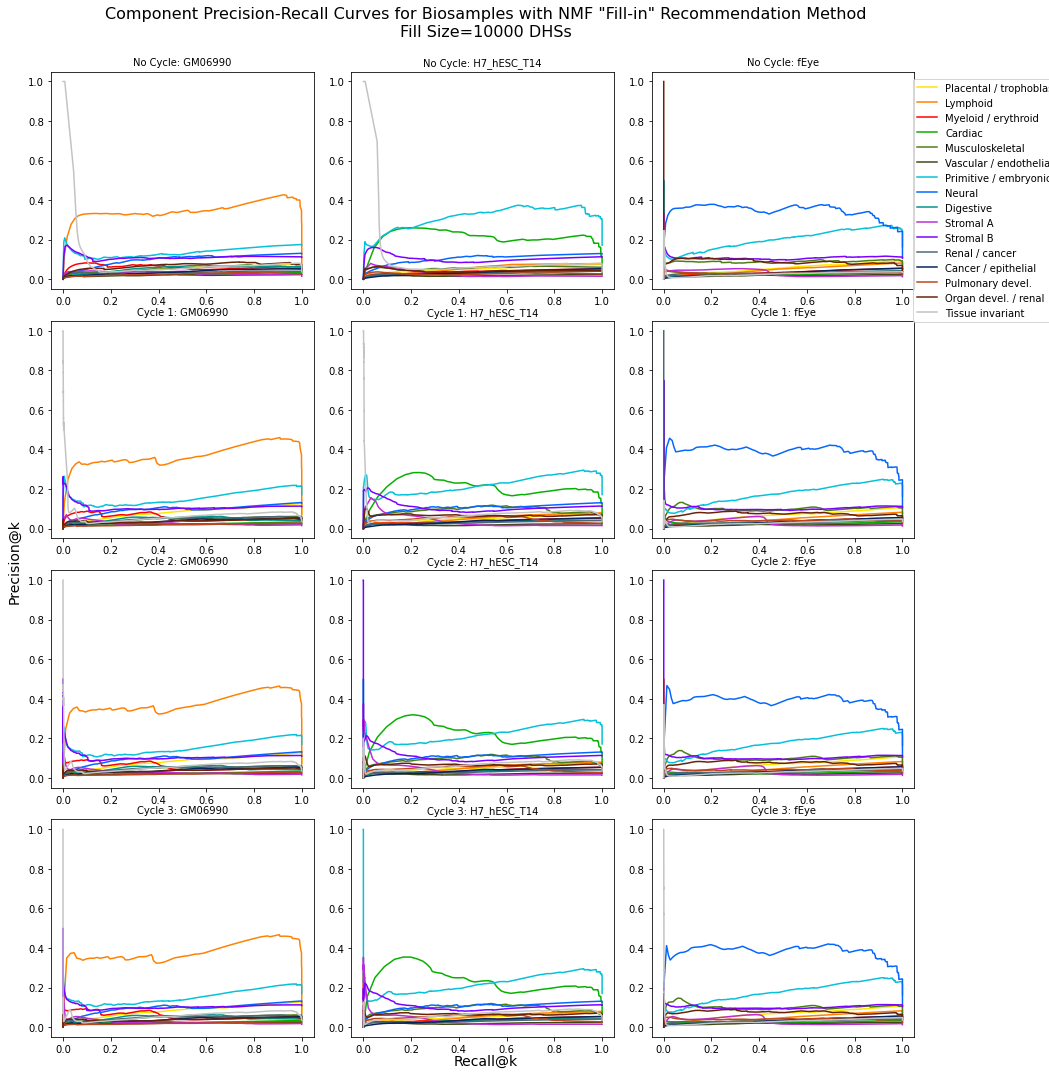

In [34]:
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(14,14))
fig.tight_layout()
fig.patch.set_facecolor('white')

for ax, ind in zip(fig.axes[:3], range(3)):
    for i in range(len(comps)):
        ax.plot(cycle_0_comp_recall[ind][i], cycle_0_comp_precision[ind][i], color=color[i])
    ax.set_title('No Cycle: ' + biosample_names[ind], fontsize=10)

for ax, ind in zip(fig.axes[3:6], range(3)):
    for i in range(len(comps)):
        ax.plot(cycle_1_comp_recall[ind][i], cycle_1_comp_precision[ind][i], color=color[i])
    ax.set_title('Cycle 1: ' + biosample_names[ind], fontsize=10)
    
for ax, ind in zip(fig.axes[6:9], range(3)):
    for i in range(len(comps)):
        ax.plot(cycle_2_comp_recall[ind][i], cycle_2_comp_precision[ind][i], color=color[i])
    ax.set_title('Cycle 2: ' + biosample_names[ind], fontsize=10)
    
for ax, ind in zip(fig.axes[9:12], range(3)):
    for i in range(len(comps)):
        ax.plot(cycle_3_comp_recall[ind][i], cycle_3_comp_precision[ind][i], color=color[i])
    ax.set_title('Cycle 3: ' + biosample_names[ind], fontsize=10)


fig.subplots_adjust(right=0.89)
# lines, labels = fig.axes[-1].get_legend_handles_labels()
fig.legend(comps, loc = (0.87, 0.7))
# print(lines)
fig.suptitle('Component Precision-Recall Curves for Biosamples with NMF "Fill-in" Recommendation Method\nFill Size=10000 DHSs', fontsize=16, x=0.465, y=1.05)
# fig.xlabel('Recall@k')
# fig.ylabel('Precision@k')
fig.text(0.465, 0, 'Recall@k', ha='center', fontsize=14)
fig.text(-0.01, 0.5, 'Precision@k', va='center', rotation='vertical', fontsize=14)

In [35]:
#finding AUC values for each component of each cycle 1 biosample
cycle_0_total_auc = []
for i in range(len(cycle_0_comp_precision)):
    comp_auc = []
    for j in range(len(cycle_0_comp_precision[i])):
        comp_auc.append(auc(cycle_0_comp_recall[i][j], cycle_0_comp_precision[i][j]))
    cycle_0_total_auc.append(comp_auc)

In [36]:
#finding AUC values for each component of each cycle 1 biosample
cycle_1_total_auc = []
for i in range(len(cycle_1_comp_precision)):
    comp_auc = []
    for j in range(len(cycle_1_comp_precision[i])):
        comp_auc.append(auc(cycle_1_comp_recall[i][j], cycle_1_comp_precision[i][j]))
    cycle_1_total_auc.append(comp_auc)

In [37]:
#finding AUC values for each component of each cycle 2 biosample
cycle_2_total_auc = []
for i in range(len(cycle_2_comp_precision)):
    comp_auc = []
    for j in range(len(cycle_2_comp_precision[i])):
        comp_auc.append(auc(cycle_2_comp_recall[i][j], cycle_2_comp_precision[i][j]))
    cycle_2_total_auc.append(comp_auc)

In [38]:
#finding AUC values for each component of each cycle 3 biosample
cycle_3_total_auc = []
for i in range(len(cycle_3_comp_precision)):
    comp_auc = []
    for j in range(len(cycle_3_comp_precision[i])):
        comp_auc.append(auc(cycle_3_comp_recall[i][j], cycle_3_comp_precision[i][j]))
    cycle_3_total_auc.append(comp_auc)

Text(0.465, 1.05, 'Component PR Curve AUC Values for Biosamples with NMF "Fill-in" Recommendation Method\nFill Size=10000 DHSs')

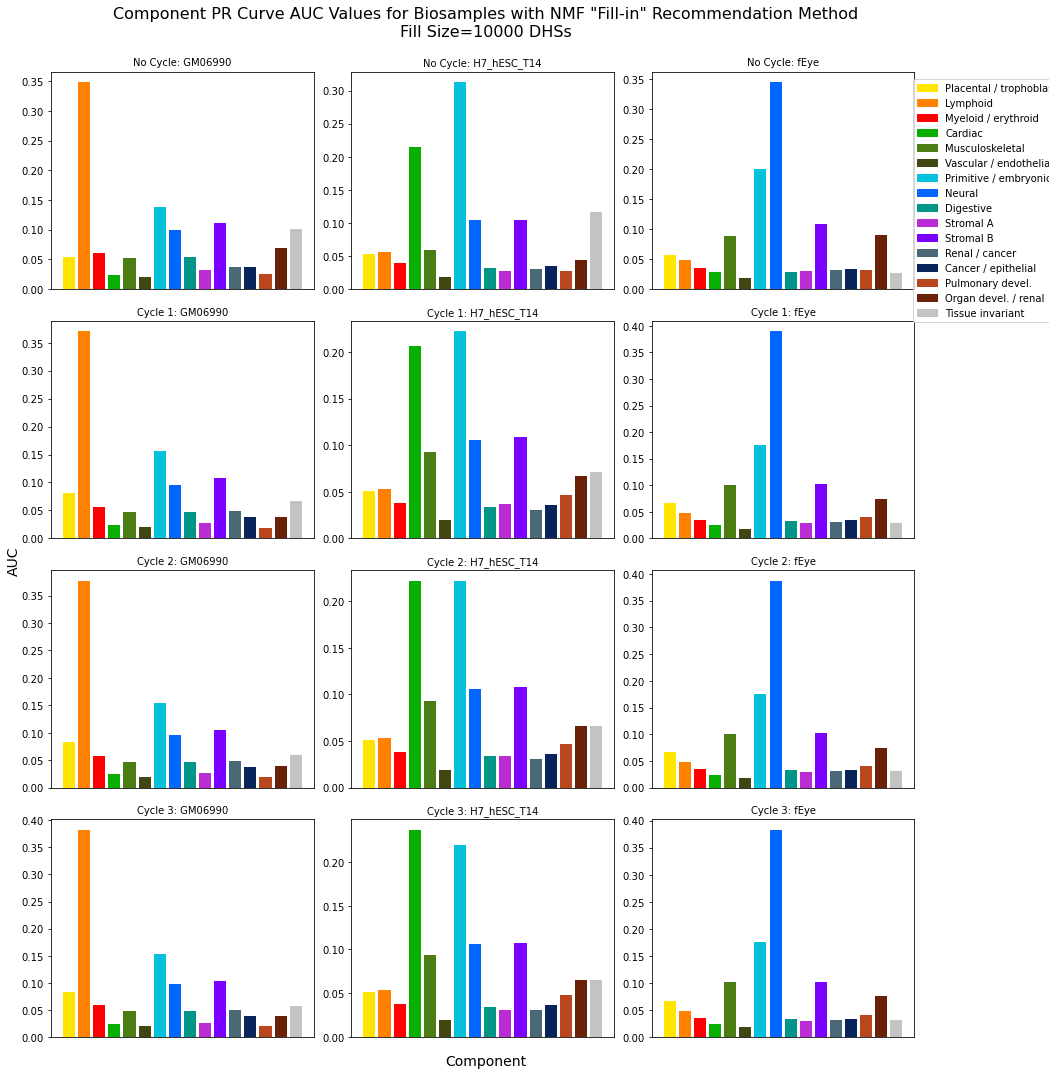

In [39]:
#plotting component PR curve AUC values
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(14,14))
fig.tight_layout()
fig.patch.set_facecolor('white')

for ax, ind in zip(fig.axes[:3], range(3)):
    ax.bar(comps, cycle_0_total_auc[ind], color=color)
    ax.set_title('No Cycle: ' + biosample_names[ind], fontsize=10)
    ax.set_xticks([])

for ax, ind in zip(fig.axes[3:6], range(3)):
    ax.bar(comps, cycle_1_total_auc[ind], color=color)
    ax.set_title('Cycle 1: ' + biosample_names[ind], fontsize=10)
    ax.set_xticks([])
    
for ax, ind in zip(fig.axes[6:9], range(3)):
    ax.bar(comps, cycle_2_total_auc[ind], color=color)
    ax.set_title('Cycle 2: ' + biosample_names[ind], fontsize=10)
    ax.set_xticks([])
    
for ax, ind in zip(fig.axes[9:12], range(3)):
    ax.bar(comps, cycle_3_total_auc[ind], color=color)
    ax.set_title('Cycle 3: ' + biosample_names[ind], fontsize=10)
    ax.set_xticks([])
    
fig.subplots_adjust(right=0.89)
# lines, labels = fig.axes[-1].get_legend_handles_labels()

handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
fig.legend(handles, comps, loc = (0.87, 0.7))
# print(lines)
# fig.xlabel('Recall@k')
# fig.ylabel('Precision@k')
fig.text(0.465, 0, 'Component', ha='center', fontsize=14)
fig.text(-0.01, 0.5, 'AUC', va='center', rotation='vertical', fontsize=14)
fig.suptitle('Component PR Curve AUC Values for Biosamples with NMF "Fill-in" Recommendation Method\nFill Size=10000 DHSs', fontsize=16, x=0.465, y=1.05)

**Fill in (add positives) function**

In [12]:
#Takes in Biosample and DHS decompositions, the full dhs presence absence matrix, a cut size, and a number
#of cycles. Generates recommendations for each biosample and fills in dhs matrix with the value 1 for the first 
#"cut_size" recommendations. New NMF decompositions are generated for the new data. This repeats for each cycle.
#The new DHS array and the new decomposition results
def fill_in_add_positives(Basis=decomp_Basis, Mixture=decomp_Mixture, dhs_arr=dhs_array, cut_size=1000, cycles=1):
    n_biosamples, n_biosample_e = Basis.shape
    n_DHS_e, n_DHSs = Mixture.shape
    for i in range(cycles):
        print('Starting Cycle %s / %s' %(i+1, cycles))
        #finding known positives for all biosamples
        full_kp = np.where(dhs_arr==1)
        #Generate scores for each interaction
        scores = np.dot(Basis, Mixture)
        #sorting scores for each biosample
        sorted_scores = np.argsort(-scores, axis=1)
        updated_dhs_array = np.copy(dhs_arr)
        #for each row, updating DHS entries based on top predicted scores (ie top cut_size DHS indices=1)
        for biosample in range(n_biosamples):
            filtered_sorted_scores = np.delete(sorted_scores[biosample], np.where(np.isin(sorted_scores[biosample], full_kp[1][full_kp[0]==biosample])))
            first_cut_dhss = filtered_sorted_scores[:cut_size]
            updated_dhs_array[biosample, first_cut_dhss] = 1
            
        #regenerate NMF decompositions
        print('difference check:', np.sum(np.sum(updated_dhs_array-dhs_arr, axis=1)))
        print('NMF Decomposition:')
        new_decomp_Basis, new_decomp_Mixture, n_iter = non_negative_factorization(updated_dhs_array, W=Basis, H=Mixture, n_components=16, init='custom', random_state=3, max_iter=400, verbose=1)
        dhs_arr = updated_dhs_array
        Basis = new_decomp_Basis
        Mixture = new_decomp_Mixture

#     new_dhs = pd.DataFrame(updated_dhs_array)
    return updated_dhs_array, new_decomp_Basis, new_decomp_Mixture

**Fill in function (keep biosample proportions)**

In [98]:
#Takes in Biosample and DHS decompositions, the full dhs presence absence matrix and a number
#of cycles. Generates recommendations for each biosample and fills in dhs matrix with the value 1 
#for the top # of predicted DHSs where # is the original number of known positives for that biosample.
#The number of New NMF decompositions are generated for the new data. This repeats for each cycle.
#The new DHS array and the new decomposition results
def fill_in_keep_proportions(Basis=decomp_Basis, Mixture=decomp_Mixture, dhs_arr=dhs_array, cycles=1):
    n_biosamples, n_biosample_e = Basis.shape
    n_DHS_e, n_DHSs = Mixture.shape
    for i in range(cycles):
        print('Starting Cycle %s / %s' %(i+1, cycles))
        #Generate scores for each interaction
        scores = np.dot(Basis, Mixture)
        #sorting scores for each biosample
        sorted_scores = np.argsort(-scores, axis=1)
        #for each row, updating DHS entries based on top predicted scores (keep same positive proportions)
        updated_dhs_array = np.zeros((n_biosamples, n_DHSs), dtype=int)
        for biosample in range(n_biosamples):
            kp_num = np.sum(dhs_arr[biosample])
            top_dhss = sorted_scores[biosample, :kp_num]
            updated_dhs_array[biosample, top_dhss] = 1
            
        #regenerate NMF decompositions
        print('NMF Decomposition:')
        new_decomp_Basis, new_decomp_Mixture, n_iter = non_negative_factorization(updated_dhs_array, W=Basis, H=Mixture, n_components=16, init='custom', random_state=3, max_iter=400, verbose=1)
        dhs_arr = updated_dhs_array
        Basis = new_decomp_Basis
        Mixture = new_decomp_Mixture

#     new_dhs = pd.DataFrame(updated_dhs_array)
    return updated_dhs_array, new_decomp_Basis, new_decomp_Mixture

**Fill in (decision boundary) Function**

In [8]:
#Takes in Biosample and DHS decompositions and a number of cycles. These decompositions are used to 
#reconstruct the DHS matrix on which a decision boundary is applied. From this presence/absence matrix,
#new NMF decompositions are calculated. The new presence/absence matrix, the new Basis decomposition, and
#the new Mixture decomposition are returned.
def fill_in_decision_boundary(Basis=decomp_Basis, Mixture=decomp_Mixture, cycles=1):
    for i in range(cycles):
        print('Starting Cycle %s / %s' %(i+1, cycles))
        #Generate scores for each interaction
        scores = np.dot(Basis, Mixture)
        scores_pres_abs = np.where(scores>0.35, 1, 0)
            
        #regenerate NMF decompositions
        print('NMF Decomposition:')
        new_decomp_Basis, new_decomp_Mixture, n_iter = non_negative_factorization(scores_pres_abs, W=Basis, H=Mixture, n_components=16, init='custom', random_state=3, max_iter=400, verbose=1)
        Basis = new_decomp_Basis
        Mixture = new_decomp_Mixture

#     new_dhs = pd.DataFrame(updated_dhs_array)
    return scores_pres_abs, new_decomp_Basis, new_decomp_Mixture

**Fill in (delta)**

In [3]:
def fill_in_delta(Basis=decomp_Basis, Mixture=decomp_Mixture, dhs_arr=dhs_array, cycles=1, flip=0.01):
    n_biosamples, n_biosample_e = Basis.shape
    n_DHS_e, n_DHSs = Mixture.shape
    for i in range(cycles):
        print('Starting Cycle %s / %s' %(i+1, cycles))
        #Generate scores for each interaction
        print('Reconstructing DHS Matrix...')
        scores = np.dot(Basis, Mixture)
        #finding delta values between most recent presence/absence matrix and the reconstructed matrix
        diff = scores - dhs_arr #think about this - currently I am comparing scores to the most recent DHS matrix, but would it be better to compare to the original?
        updated_dhs_array = np.copy(dhs_arr)
        flip_size = int(np.round((n_DHSs*n_biosamples*flip)))
        print('Updating presence/absence matrix...')
        updated_dhs_array_flat = updated_dhs_array.flatten()
        diff_flat = diff.flatten()
        print('Sorting...')
        sorted_diff_flat = np.argsort(diff_flat)
        #indices to set to 0
        to_0_inds = sorted_diff_flat[:flip_size]
        updated_dhs_array_flat[to_0_inds] = 0
        #indices to set to 1
        to_1_inds = sorted_diff_flat[-flip_size:]
        updated_dhs_array_flat[to_1_inds] = 1
        updated_dhs_array = updated_dhs_array_flat.reshape((n_biosamples, n_DHSs))
        
        
#         for biosample in range(n_biosamples):
            #sorting delta values for each biosample
#             sorted_diff_biosample = np.argsort(diff[biosample])
            #indices to set to 0
#             to_0_inds = sorted_diff_biosample[:flip_size]
#             updated_dhs_array[biosample, to_0_inds] = 0
            #indices to set to 1
#             to_1_inds = sorted_diff_biosample[-flip_size:]
#             updated_dhs_array[biosample, to_1_inds] = 1
        #regenerate NMF decompositions
        print()
        print('NMF Decomposition:')
        new_decomp_Basis, new_decomp_Mixture, n_iter = non_negative_factorization(updated_dhs_array, W=Basis, H=Mixture, n_components=16, init='custom', random_state=3, max_iter=400, verbose=1)
        dhs_arr = updated_dhs_array
        Basis = new_decomp_Basis
        Mixture = new_decomp_Mixture
    return updated_dhs_array, new_decomp_Basis, new_decomp_Mixture

**Fill in (remove positives) Function**

In [ ]:
#Takes in Biosample and DHS decompositions, the full dhs presence absence matrix, a cut size, and a number
#of cycles. Generates recommendations for each biosample and fills in dhs matrix with the value 1 for the first 
#"cut_size" recommendations. New NMF decompositions are generated for the new data. This repeats for each cycle.
#The new DHS array and the new decomposition results
def fill_in_remove_positives(Basis=decomp_Basis, Mixture=decomp_Mixture, dhs_arr=dhs_array, cut_size=1000, cycles=1):
    n_biosamples, n_biosample_e = Basis.shape
    n_DHS_e, n_DHSs = Mixture.shape
    for i in range(cycles):
        print('Starting Cycle %s / %s' %(i+1, cycles))
        #finding known positives for all biosamples
        full_kp = np.where(dhs_arr==1)
        updated_dhs_array = np.copy(dhs_arr)
        #randomly remove 'cut_size' number of DHSs from each biosample
        for biosample in range(n_biosamples):
            biosample_kp = full_kp[1][full_kp[0]==biosample]
            random_kp_inds = random.sample(range(0, len(biosample_kp)), cut_size)
            random_kp_interactions = biosample_kp[random_kp_inds]
            updated_dhs_array[biosample, random_kp_interactions] = 0
            
        #regenerate NMF decompositions
        print('difference check:', np.sum(np.sum(updated_dhs_array-dhs_arr, axis=1)))
        print('NMF Decomposition:')
        new_decomp_Basis, new_decomp_Mixture, n_iter = non_negative_factorization(updated_dhs_array, W=Basis, H=Mixture, n_components=16, init='custom', random_state=3, max_iter=400, verbose=1)
        dhs_arr = updated_dhs_array
        Basis = new_decomp_Basis
        Mixture = new_decomp_Mixture

#     new_dhs = pd.DataFrame(updated_dhs_array)
    return updated_dhs_array, new_decomp_Basis, new_decomp_Mixture

**Functions needed to generate recommendations**

In [9]:
# new_DHS_e[:, np.array(DHSs_to_recommend_from)]
x = np.array([2, 4, 1, 6, 3])
x1 = pd.Series(x)
y = np.array([0, 1, 2, 3, 4])
x1[y]

0    2
1    4
2    1
3    6
4    3
dtype: int64

In [27]:
np.sort(x)

array([1, 2, 3, 4, 6])

In [6]:
biosamples = ['GM06990']
biosample_e=decomp_Basis
DHS_e=decomp_Mixture
dhs_df=dhs
heatmap_comps=comps_for_heatmap
new_biosample_e=decomp_Basis
new_DHS_e=decomp_Mixture

#number of biosamples and DHSs in dataset
n_biosamples, n_biosample_e = biosample_e.shape
n_DHS_e, n_DHSs = DHS_e.shape
return_list = []
metadata = DHS_metadata.reset_index()
comp_ser = metadata['component']
chrom_ser = metadata['seqname']
start_ser = metadata['start']
end_ser = metadata['end']
numsamples_ser = metadata['numsamples']
identifier_ser = metadata['identifier']


#generate DHS recommendations for each biosample
for biosample_name in biosamples:
    if isinstance(biosample_name, str):
        biosample = list(biosample_df[biosample_df['Biosample name']==biosample_name]['library order'])[0] - 1
            
    else:
        biosample = biosample_name
        if (biosample > 732) & (n_biosamples == 747): #Pancreatic Cancer data
            relative_num = biosample - 733
            biosample_name = pc_sample_names[relative_num]
        elif (biosample > 732) & (n_biosamples == 771): #Immune data
            relative_num = biosample - 733
            biosample_name = immune_sample_names[relative_num]
        else:
            biosample_name = list(biosample_df[biosample_df['library order']==biosample+1]['Biosample name'])[0]
        
    top_comp = np.argmax(biosample_e[biosample, :])
    print('This is a %s Biosample' %(heatmap_comps[top_comp]))
        
    #DHSs known to relate to the biosample
    #indices
    known_positives = [i for i, dhs_pos in enumerate(list(dhs_df.T[biosample])) if dhs_pos == 1]
#         print(len(known_positives))
        
    #filter out known positives from what will be recommended
    new_DHS_e_top_comps = np.argmax(new_DHS_e, axis=0).astype('float')
    new_DHS_e_sum = np.sum(new_DHS_e, axis=0)
    all_0_inds = np.where(new_DHS_e_sum==0)[0]
    new_DHS_e_top_comps[all_0_inds] = np.nan
    DHSs_to_recommend_from = np.where(new_DHS_e_top_comps==float(top_comp))[0]
    DHSs_to_recommend_from = list(set(DHSs_to_recommend_from) - set(known_positives))
    
    DHSs_to_recommend_from = np.sort(DHSs_to_recommend_from)
    
    nki_series = pd.Series(DHSs_to_recommend_from)
        
    #DHSs model predictions that relate to biosample
    filtered_scores = np.dot(new_biosample_e[biosample, :], new_DHS_e[:, np.array(DHSs_to_recommend_from)])
        

    #rank from most related to least
    #not DHS indices
    filtered_top_DHSs_o = [np.argsort(-filtered_scores)][0]
    top_rec_DHSs_o = nki_series[filtered_top_DHSs_o]
    top_filtered_scores_o = filtered_scores[filtered_top_DHSs_o]

This is a Lymphoid Biosample


In [20]:
top_rec_DHSs_o

79747     1139297
197967    2781805
70321     1024597
48193      697632
49810      721315
           ...   
217758    3068548
215918    3039027
102870    1440388
60459      867449
65578      952621
Length: 254762, dtype: int64

In [18]:
# list(top_rec_DHSs_o)[-100:]

In [21]:
top_rec_DHSs

43442     1139297
77019     2781805
243371    1024597
84294      697632
96398      721315
           ...   
237570     487377
83888     3318454
75013      681117
102398     208765
42538     1661353
Length: 254762, dtype: int64

In [19]:
# list(top_rec_DHSs)[-100:]

In [14]:
comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']

def heatmap_recommendations(biosamples, signal_data, new_biosample_e, new_DHS_e, print_num=3, biosample_e=decomp_Basis, DHS_e=decomp_Mixture, dhs_df=dhs, ROIurl=False, comps_to_filter_out=[], heatmap_comps=comps_for_heatmap): #, full_data=gd_coo
    
    #number of biosamples and DHSs in dataset
    n_biosamples, n_biosample_e = biosample_e.shape
    n_DHS_e, n_DHSs = DHS_e.shape
    return_list = []
    metadata = DHS_metadata.reset_index()
    comp_ser = metadata['component']
    chrom_ser = metadata['seqname']
    start_ser = metadata['start']
    end_ser = metadata['end']
    numsamples_ser = metadata['numsamples']
    identifier_ser = metadata['identifier']
    
    #generate DHS recommendations for each biosample
    for biosample_name in biosamples:
        if isinstance(biosample_name, str):
            biosample = list(biosample_df[biosample_df['Biosample name']==biosample_name]['library order'])[0] - 1
            
        else:
            biosample = biosample_name
            if (biosample > 732) & (n_biosamples == 747): #Pancreatic Cancer data
                relative_num = biosample - 733
                biosample_name = pc_sample_names[relative_num]
            elif (biosample > 732) & (n_biosamples == 771): #Immune data
                relative_num = biosample - 733
                biosample_name = immune_sample_names[relative_num]
            else:
                biosample_name = list(biosample_df[biosample_df['library order']==biosample+1]['Biosample name'])[0]
        
        top_comp = np.argmax(biosample_e[biosample, :])
        print('This is a %s Biosample' %(heatmap_comps[top_comp]))
        
        #DHSs known to relate to the biosample
        #indices
        known_positives = [i for i, dhs_pos in enumerate(list(dhs_df.T[biosample])) if dhs_pos == 1]
#         print(len(known_positives))
        
        #filter out known positives from what will be recommended
        new_DHS_e_top_comps = np.argmax(new_DHS_e, axis=0).astype('float')
        new_DHS_e_sum = np.sum(new_DHS_e, axis=0)
        all_0_inds = np.where(new_DHS_e_sum==0)[0]
        new_DHS_e_top_comps[all_0_inds] = np.nan
        DHSs_to_recommend_from = np.where(new_DHS_e_top_comps==float(top_comp))[0]
        DHSs_to_recommend_from = list(set(DHSs_to_recommend_from) - set(known_positives))
        
        #sorting DHSs to recommend from (not necessary)
#         DHSs_to_recommend_from = np.sort(DHSs_to_recommend_from)
        
        nki_series = pd.Series(DHSs_to_recommend_from)
        
        #DHSs model predictions that relate to biosample
        filtered_scores = np.dot(new_biosample_e[biosample, :], new_DHS_e[:, np.array(DHSs_to_recommend_from)])
        

        #rank from most related to least
        #not DHS indices
        filtered_top_DHSs = [np.argsort(-filtered_scores)][0]
        top_rec_DHSs = nki_series[filtered_top_DHSs]
        top_filtered_scores = filtered_scores[filtered_top_DHSs]
        
        comp_rec = list(comp_ser[top_rec_DHSs])
        chrom_rec = list(chrom_ser[top_rec_DHSs])
        start_rec = list(start_ser[top_rec_DHSs])
        end_rec = list(end_ser[top_rec_DHSs])
        numsamples_rec = list(numsamples_ser[top_rec_DHSs])
        identifier_rec = list(identifier_ser[top_rec_DHSs])
        
        count = 0
        total_count = 0
        return_biosample = []
        return_biosample.append(comp_rec)
        return_biosample.append(chrom_rec)
        return_biosample.append(start_rec)
        return_biosample.append(end_rec)
        return_biosample.append(numsamples_rec)
        return_biosample.append(list(top_rec_DHSs))
        return_biosample.append(list(top_filtered_scores))
        
        if comps_to_filter_out:
            return_biosample = filter_out_recs(return_biosample, comps_to_filter_out)
        
        return_list.append(return_biosample)
        
        #print results
        print('Biosample: %s (%s)' %(biosample_name, str(biosample)))
        
        if ROIurl == True:
            #creating ROIurl link
            if comps_to_filter_out:
                link_path = make_roi_url(biosample_name, str(biosample) + '_filtered', return_biosample)
            else:
                link_path = make_roi_url(biosample_name, str(biosample) + '_all_delta_0001_3_cycles', return_biosample)
            print(link_path)
        
        if print_num > 0:
            print('   Number of Known DHSs: %s' %(len(known_positives)))
            print()
            print('   Recommended DHS Locations: ') 
            print('   Location | Component | Number of Samples | Biosample Signal/Average Signal | Left +DHS Signal | Right +DHS Signal')
        
        
        
            dhs_ids = top_rec_DHSs.to_numpy()
            #dhs to the right of recommended dhs
            dhs_right = dhs_ids[:]+1
            #dhs to the left of recommended dhs
            dhs_left = dhs_ids[:]-1
        
            #removing dhss that are "neighbored" across chromosomes
            chrm_list = list(np.unique(list(DHS_metadata['seqname'])))
            rows_per_chrm = [0]
            for chrm in chrm_list:
                max_row = max(rows_per_chrm)
                rows, col = DHS_metadata[DHS_metadata['seqname']==chrm].shape
                rows_per_chrm.append(rows + max_row)
            rows_per_chrm = np.array(rows_per_chrm)
        
            dhs_right = np.delete(dhs_right, np.isin(dhs_right, rows_per_chrm))
            dhs_left = np.delete(dhs_left, np.isin(dhs_left, rows_per_chrm-1))
        
            #determining presence/absense of dhss to right and left of recommended dhs
            right = dhs_array[biosample, dhs_right] 
            left = dhs_array[biosample, dhs_left]
        
            #signal data
            sample_rec_dhs_signal, rec_dhs_signal, rec_identifier = signal_values(list(top_rec_DHSs), signal_data)
            sample_right_dhs_signal, right_dhs_signal, right_identifier = signal_values(list(dhs_right), signal_data)
            sample_left_dhs_signal, left_dhs_signal, left_identifier = signal_values(list(dhs_left), signal_data)

        
        
            for i in range(print_num):
                chrom = chrom_rec[i]
                start = start_rec[i]
                end = end_rec[i]
                component = comp_rec[i]
                num_samples = numsamples_rec[i]
                sample_rec_dhs_signal_i = round(list(sample_rec_dhs_signal)[i], 3)
                rec_dhs_signal_i = round(float(list(rec_dhs_signal)[i]), 3)
                dhs_id = list(top_rec_DHSs)[i]
                right_id = list(np.where(dhs_right == dhs_id+1))[0] #+1
                if list(right_id) and right[right_id]==1:
                    sample_right_dhs_signal_i = round(sample_right_dhs_signal[int(right_id[0])], 3)
                    right_dhs_signal_i = round(right_dhs_signal[int(right_id[0])], 3)
                    right_print = str(round(sample_right_dhs_signal_i, 3)) + '/' + str(round(right_dhs_signal_i, 3))
                else:
                    right_print = 'N/A'
            
                left_id = list(np.where(dhs_left == dhs_id-1))[0]
                if list(left_id) and left[left_id]==1:
                    sample_left_dhs_signal_i = round(sample_left_dhs_signal[int(left_id[0])], 3)
                    left_dhs_signal_i = round(left_dhs_signal[int(left_id[0])], 3)
                    left_print = str(round(sample_left_dhs_signal_i, 3)) + '/' + str(round(left_dhs_signal_i, 3))
                else:
                    left_print = 'N/A'
                
                
                print('      %s:%s-%s | %s | %s | %s/%s | %s | %s'
                      %(chrom, start, end, component, num_samples, sample_rec_dhs_signal_i, rec_dhs_signal_i,
                       left_print, right_print))

    return return_list

In [6]:




#function to recommend DHSs for a given biosample. Takes in the model, data, and a list of
#biosamples for DHSs to be recommend for. For each biosample, prints out known associated DHSs
#and a list of recommended DHSs. Function modeled after tutorial 3, 'Recommendation Systems
#- Learn Python for Data Science' on LightFM github. 

def sample_recommendation(biosamples, signal_data, print_num=3, biosample_e=decomp_Basis, DHS_e=decomp_Mixture, dhs_df=dhs, ROIurl=False, comps_to_filter_out=[]): #, full_data=gd_coo
    
    #number of biosamples and DHSs in dataset
    n_biosamples, n_biosample_e = biosample_e.shape
    n_DHS_e, n_DHSs = DHS_e.shape
    return_list = []
    metadata = DHS_metadata.reset_index()
    comp_ser = metadata['component']
    chrom_ser = metadata['seqname']
    start_ser = metadata['start']
    end_ser = metadata['end']
    numsamples_ser = metadata['numsamples']
    identifier_ser = metadata['identifier']
    
    #generate DHS recommendations for each biosample
    for biosample_name in biosamples:
        if isinstance(biosample_name, str):
            biosample = list(biosample_df[biosample_df['Biosample name']==biosample_name]['library order'])[0] - 1
            
        else:
            biosample = biosample_name
            if (biosample > 732) & (n_biosamples == 747): #Pancreatic Cancer data
                relative_num = biosample - 733
                biosample_name = pc_sample_names[relative_num]
            elif (biosample > 732) & (n_biosamples == 771): #Immune data
                relative_num = biosample - 733
                biosample_name = immune_sample_names[relative_num]
            else:
                biosample_name = list(biosample_df[biosample_df['library order']==biosample+1]['Biosample name'])[0]
            
        
        #DHSs known to relate to the biosample
        #indices
        known_positives = [i for i, dhs_pos in enumerate(list(dhs_df.T[biosample])) if dhs_pos == 1]
        print(len(known_positives))
        
        #filter out known positives from what will be recommended
        not_known_ind = list(set(np.arange(n_DHSs)) - set(known_positives))
        
        nki_series = pd.Series(not_known_ind)
        
        #DHSs model predictions that relate to biosample
        filtered_scores = np.dot(biosample_e[biosample, :], DHS_e[:, np.array(not_known_ind)])
        

        #rank from most related to least
        #not DHS indices
        filtered_top_DHSs = [np.argsort(-filtered_scores)][0]
        top_rec_DHSs = nki_series[filtered_top_DHSs]
        top_filtered_scores = filtered_scores[filtered_top_DHSs]
        
        comp_rec = list(comp_ser[top_rec_DHSs])
        chrom_rec = list(chrom_ser[top_rec_DHSs])
        start_rec = list(start_ser[top_rec_DHSs])
        end_rec = list(end_ser[top_rec_DHSs])
        numsamples_rec = list(numsamples_ser[top_rec_DHSs])
        identifier_rec = list(identifier_ser[top_rec_DHSs])
        
        count = 0
        total_count = 0
        return_biosample = []
        return_biosample.append(comp_rec)
        return_biosample.append(chrom_rec)
        return_biosample.append(start_rec)
        return_biosample.append(end_rec)
        return_biosample.append(numsamples_rec)
        return_biosample.append(list(top_rec_DHSs))
        return_biosample.append(list(top_filtered_scores))
        
        if comps_to_filter_out:
            return_biosample = filter_out_recs(return_biosample, comps_to_filter_out)
        
        return_list.append(return_biosample)
        
        #print results
        print('Biosample: %s (%s)' %(biosample_name, str(biosample)))
        
        if ROIurl == True:
            #creating ROIurl link
            if comps_to_filter_out:
                link_path = make_roi_url(biosample_name, str(biosample) + '_filtered', return_biosample)
            else:
                link_path = make_roi_url(biosample_name, str(biosample) + '_cycle3', return_biosample)
            print(link_path)
        
        if print_num > 0:
            print('   Number of Known DHSs: %s' %(len(known_positives)))
            print()
            print('   Recommended DHS Locations: ') 
            print('   Location | Component | Number of Samples | Biosample Signal/Average Signal | Left +DHS Signal | Right +DHS Signal')
        
        
        
            dhs_ids = top_rec_DHSs.to_numpy()
            #dhs to the right of recommended dhs
            dhs_right = dhs_ids[:]+1
            #dhs to the left of recommended dhs
            dhs_left = dhs_ids[:]-1
        
            #removing dhss that are "neighbored" across chromosomes
            chrm_list = list(np.unique(list(DHS_metadata['seqname'])))
            rows_per_chrm = [0]
            for chrm in chrm_list:
                max_row = max(rows_per_chrm)
                rows, col = DHS_metadata[DHS_metadata['seqname']==chrm].shape
                rows_per_chrm.append(rows + max_row)
            rows_per_chrm = np.array(rows_per_chrm)
        
            dhs_right = np.delete(dhs_right, np.isin(dhs_right, rows_per_chrm))
            dhs_left = np.delete(dhs_left, np.isin(dhs_left, rows_per_chrm-1))
        
            #determining presence/absense of dhss to right and left of recommended dhs
            right = dhs_array[biosample, dhs_right] 
            left = dhs_array[biosample, dhs_left]
        
            #signal data
            sample_rec_dhs_signal, rec_dhs_signal, rec_identifier = signal_values(list(top_rec_DHSs), signal_data)
            sample_right_dhs_signal, right_dhs_signal, right_identifier = signal_values(list(dhs_right), signal_data)
            sample_left_dhs_signal, left_dhs_signal, left_identifier = signal_values(list(dhs_left), signal_data)

        
        
            for i in range(print_num):
                chrom = chrom_rec[i]
                start = start_rec[i]
                end = end_rec[i]
                component = comp_rec[i]
                num_samples = numsamples_rec[i]
                sample_rec_dhs_signal_i = round(list(sample_rec_dhs_signal)[i], 3)
                rec_dhs_signal_i = round(float(list(rec_dhs_signal)[i]), 3)
                dhs_id = list(top_rec_DHSs)[i]
                right_id = list(np.where(dhs_right == dhs_id+1))[0] #+1
                if list(right_id) and right[right_id]==1:
                    sample_right_dhs_signal_i = round(sample_right_dhs_signal[int(right_id[0])], 3)
                    right_dhs_signal_i = round(right_dhs_signal[int(right_id[0])], 3)
                    right_print = str(round(sample_right_dhs_signal_i, 3)) + '/' + str(round(right_dhs_signal_i, 3))
                else:
                    right_print = 'N/A'
            
                left_id = list(np.where(dhs_left == dhs_id-1))[0]
                if list(left_id) and left[left_id]==1:
                    sample_left_dhs_signal_i = round(sample_left_dhs_signal[int(left_id[0])], 3)
                    left_dhs_signal_i = round(left_dhs_signal[int(left_id[0])], 3)
                    left_print = str(round(sample_left_dhs_signal_i, 3)) + '/' + str(round(left_dhs_signal_i, 3))
                else:
                    left_print = 'N/A'
                
                
                print('      %s:%s-%s | %s | %s | %s/%s | %s | %s'
                      %(chrom, start, end, component, num_samples, sample_rec_dhs_signal_i, rec_dhs_signal_i,
                       left_print, right_print))

    return return_list

#takes in recommendation info for a single biosample and the component to calculate precision values for.
#Returns precision values for this component
def component_precision_multiple_k(rec_info, target_comp, k_vals):
    comps = np.array(rec_info[0])
#     print(comps)
    comps_np = np.where(comps == target_comp, 1, 0)
#     print(comps_np)
    total_of_comp = np.sum(comps_np)
#     print(total_of_comp)
    count_list = []
    for k in k_vals:
        comp_k = comps_np[:k]
        count = np.sum(comp_k)
        count_list.append(count)
    counts = np.array(count_list)
    precision = counts/k_vals
    recall = counts/total_of_comp
    return precision, recall

#creates ROIurl links for recommended DHSs
def make_roi_url(biosample_name, biosample, rec_info):
    today = date.today()
    bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_' + str(biosample_name) + '_' + str(biosample) + '_recs_CT' + today.strftime("%Y%m%d") + '.bed')
    f= open(bed_path_name, 'w')
    for i in range(100):
        f.write(rec_info[1][i] + '\t' + str(rec_info[2][i]) + '\t' + str(rec_info[3][i]) + '\t' + rec_info[0][i] + '\n')
    f.close()
    link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_' + str(biosample_name) + '_' + str(biosample) + '_recs_CT' + today.strftime("%Y%m%d") + '.bed'
    return link_path

def filter_in_recs(rec_info, comps_to_filter_in):
    rec_comps = np.array(rec_info[0])
    filter_inds = []
    for comp in comps_to_filter_in:
        filter_inds.extend(list(np.where(rec_comps == comp))[0])
    leftover_ind = np.array(filter_inds)
    return_comps = list(rec_comps[leftover_ind])
    return_chrm = list(np.array(rec_info[1])[leftover_ind])
    return_start = list(np.array(rec_info[2])[leftover_ind])
    return_end = list(np.array(rec_info[3])[leftover_ind])
    return_num_samples = list(np.array(rec_info[4])[leftover_ind])
    return_top_rec_DHSs = list(np.array(rec_info[5])[leftover_ind])
    return_top_filtered_scores = list(np.array(rec_info[6])[leftover_ind])
    
    return [return_comps, return_chrm, return_start, return_end, return_num_samples, return_top_rec_DHSs, return_top_filtered_scores, list(leftover_ind)]
# filter_test = filter_in_recs(unseen_pc_rec_info[0], ['Tissue invariant'])

def filter_out_recs(rec_info, comps_to_filter_out):
    rec_comps = np.array(rec_info[0])
    filter_inds = []
    for comp in comps_to_filter_out:
        filter_inds.extend(list(np.where(rec_comps == comp))[0])
    filter_inds = set(filter_inds)
    leftover_ind = np.array(list(set(range(len(rec_comps))) - filter_inds))
    return_comps = list(rec_comps[leftover_ind])
    return_chrm = list(np.array(rec_info[1])[leftover_ind])
    return_start = list(np.array(rec_info[2])[leftover_ind])
    return_end = list(np.array(rec_info[3])[leftover_ind])
    return_num_samples = list(np.array(rec_info[4])[leftover_ind])
    return_top_rec_DHSs = list(np.array(rec_info[5])[leftover_ind])
    return_top_filtered_scores = list(np.array(rec_info[6])[leftover_ind])
    
    return [return_comps, return_chrm, return_start, return_end, return_num_samples, return_top_rec_DHSs, return_top_filtered_scores, list(leftover_ind)]
# filter_test = filter_recs(unseen_rec_info[0], ['Tissue invariant'])

#Takes in recommended DHS indices and the signal data from a single biosample. Returns the average biosample signal
#across each recommended DHS and the average signal of all biosamples at each recommended DHS. 
def signal_values(dhs, signal_data):
    identifier_series = pd.Series(signal_data['name'])
    identifier = identifier_series[dhs]
    #Average biosample signal across each recommended DHS
    mean_signal_sample_series = pd.Series(signal_data['mean'])
    mean_signal_sample = mean_signal_sample_series[dhs]
    #Average signal of all biosamples at each recommended DHS
    mean_signal_DHS_series = pd.Series(DHS_metadata['mean_signal'])
    mean_signal_DHS = mean_signal_DHS_series[dhs]
    return list(mean_signal_sample), list(mean_signal_DHS), list(identifier)

DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])

tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
df = pd.read_csv(tsv_file, delimiter="\t")
biosample_df = df[['library order', 'Biosample name']]

#reordering dataframe to match order of presence/absence matrix and DHS metadata dataframe
#first bigwig file
# GM06990_signal = pd.read_table('/home/ctrader/lightfm_data/out_ENCFF691MRD.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'mean'])

#second bigwig file
GM06990_signal = pd.read_table('/home/ctrader/lightfm_data/out_ENCFF962FBP.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'mean'])

GM06990_signal[['name']] = GM06990_signal[['name']].astype(str)
GM06990_signal = GM06990_signal.set_index('name')
id_order = DHS_metadata['identifier'].to_list()
GM06990_signal = GM06990_signal.reindex(id_order)
GM06990_signal = GM06990_signal.reset_index()

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)
/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (0) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


**Fill in DHS matrix (sandbox)**

In [4]:
scores = np.dot(new_decomp_Basis_all_delta_0001_2_cycles, new_decomp_Mixture_all_delta_0001_2_cycles)

In [5]:
diff = scores - updated_dhs_array_all_delta_0001_2_cycles

In [6]:
updated_dhs_array3 = np.copy(updated_dhs_array_all_delta_0001_2_cycles)

In [7]:
flip_size = int(np.round((n_DHSs*n_biosamples*0.0001)))

In [9]:
updated_dhs_array3_flat = updated_dhs_array3.flatten()
diff_flat = diff.flatten()

MemoryError: Unable to allocate 19.6 GiB for an array with shape (2632861234,) and data type float64

In [ ]:
sorted_diff_flat = np.argsort(diff_flat)
#indices to set to 0
to_0_inds = sorted_diff_flat[:flip_size]
updated_dhs_array3_flat[to_0_inds] = 0
#indices to set to 1
to_1_inds = sorted_diff_flat[-flip_size:]
updated_dhs_array3_flat[to_1_inds] = 1
updated_dhs_array3 = updated_dhs_array3_flat.reshape((n_biosamples, n_DHSs))

In [ ]:
new_decomp_Basis3, new_decomp_Mixture3, n_iter = non_negative_factorization(updated_dhs_array3, W=new_decomp_Basis_all_delta_0001_2_cycles, H=new_decomp_Mixture_all_delta_0001_2_cycles, n_components=16, init='custom', random_state=3, max_iter=400, verbose=1)

In [27]:
t = np.array([[1, 2, 3, 4, 5], [6, 7, 8, 9, 10], [11, 12, 13, 14, 15]])

In [28]:
t

array([[ 1,  2,  3,  4,  5],
       [ 6,  7,  8,  9, 10],
       [11, 12, 13, 14, 15]])

In [29]:
t_flat = t.flatten()

In [31]:
t0 = t_flat.reshape((t.shape))

In [33]:
t.shape

(3, 5)

In [5]:
#Generate scores for each interaction
scores = np.dot(decomp_Basis, decomp_Mixture)
scores.shape

(733, 3591898)

In [6]:
scores_flat = scores.flatten()
dhs_array_flat = dhs_array.flatten()

In [39]:
dhs_array_flat

array([0, 0, 0, ..., 0, 0, 0])

In [8]:
diff = scores_flat - dhs_array_flat

In [11]:
diff.shape

(2632861234,)

In [12]:
t = time.time()
sorted_diff_biosample = np.argsort(diff)
time.time() - t

1500.6521632671356

In [25]:
sorted_diff_biosample = 0

In [24]:
diff[1636651732]

1.9316029875636973

In [25]:
dhs_array[0, 624130]

0

In [16]:
sorted_diff = np.argsort(diff)

In [17]:
len(sorted_diff)

array([ 979936582,  916288587, 2248011564, ..., 1636400183, 1637032695,
       1636651732])

In [13]:
x = np.where(diff==-1)
len(x[0])

22450

In [14]:
n_biosamples*n_DHSs*0.05

131643061.7

In [29]:
full_kp = np.where(dhs_array==1)

In [42]:
biosample=0
biosample_kp = full_kp[1][full_kp[0]==biosample]

In [43]:
len(biosample_kp)

82918

In [42]:
scores

array([[1.54423437e-03, 0.00000000e+00, 0.00000000e+00, ...,
        1.81946976e-05, 1.37926090e-02, 1.37926090e-02],
       [1.29289766e-03, 2.21252285e-03, 0.00000000e+00, ...,
        3.76043255e-03, 2.50775685e-03, 2.50775685e-03],
       [1.58784316e-03, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 1.93769424e-02, 1.93769424e-02],
       ...,
       [1.79817489e-03, 1.43285173e-03, 0.00000000e+00, ...,
        2.69339321e-03, 3.74418953e-03, 3.74418953e-03],
       [1.58129815e-03, 4.30504270e-02, 0.00000000e+00, ...,
        6.48213320e-02, 7.99338751e-04, 7.99338751e-04],
       [1.44818009e-03, 4.93755723e-02, 0.00000000e+00, ...,
        7.42562764e-02, 6.37984283e-04, 6.37984283e-04]])

In [43]:
scores_pa = np.where(scores>0.35, 1, 0)

In [45]:
np.sum(np.sum(scores_pa, axis=0))/(n_DHSs*n_biosamples)

0.02672362146982791

In [46]:
new_decomp_Mixture_decision_boundary_1_cycle

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [17]:
diff = scores_pa - dhs_array

In [18]:
np.sum(np.sum(diff, axis=0))

-5917950

In [12]:
#finding known positives for all biosamples
# full_kp = np.where(dhs_array==1)

In [13]:
#sorting scores for each biosample
sorted_scores = np.argsort(-scores, axis=1)

In [14]:
# cut_size = 1000

In [20]:
# #for each row, updating DHS entries based on top predicted scores (ie top cut_size DHS indices=1)
# updated_dhs_array = np.copy(dhs_array)
# for biosample in range(n_biosamples):
#     filtered_sorted_scores = np.delete(sorted_scores[biosample], np.where(np.isin(sorted_scores[biosample], full_kp[1][full_kp[0]==biosample])))
#     first_cut_dhss = filtered_sorted_scores[:cut_size]
#     updated_dhs_array[biosample, first_cut_dhss] = 1

In [97]:
#for each row, updating DHS entries based on top predicted scores (keep same positive proportions)
updated_dhs_array = np.zeros((n_biosamples, n_DHSs), dtype=int)
for biosample in range(n_biosamples):
    kp_num = np.sum(dhs_array[biosample])
    top_dhss = sorted_scores[biosample, :kp_num]
    updated_dhs_array[biosample, top_dhss] = 1

In [21]:
new_dhs = pd.DataFrame(updated_dhs_array)
new_dhs.shape

(733, 3591898)

In [22]:
#regenerate NMF decompositions
new_decomp_Basis, new_decomp_Mixture, n_iter = non_negative_factorization(updated_dhs_array, W=decomp_Basis, H=decomp_Mixture, n_components=16, init='custom', random_state=3, verbose=1)

violation: 1.0
violation: 0.23706175791380216
violation: 0.10904926264049893
violation: 0.07474534232668463
violation: 0.05767576980318156
violation: 0.04678546513014218
violation: 0.03912276188767488
violation: 0.033340644385284474
violation: 0.028944327572271954
violation: 0.02549123032288676
violation: 0.022675291932511554
violation: 0.020309176066792344
violation: 0.018243672939899355
violation: 0.0164433418957074
violation: 0.01484910420497907
violation: 0.013431502600385265
violation: 0.012167728922672132
violation: 0.011039648619792956
violation: 0.010026180059922594
violation: 0.009113118168858491
violation: 0.008288711806228952
violation: 0.007544586942751981
violation: 0.006873542026561206
violation: 0.00626775210366227
violation: 0.005720696832018984
violation: 0.005226874183676665
violation: 0.004780696698075769
violation: 0.004377243549527315
violation: 0.0040125738458316445
violation: 0.003682554472682657
violation: 0.003382627725825837
violation: 0.0031097043342019366
vi

In [5]:
dhs_array

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])